# EEE4022S Thesis Project: The development of a low-cost X-ray phantom for bone suppression and radiography system calibration

## By: M Saeed Solomon (SLMMOG032)

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import pydicom
import os
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import cv2
from Modules import Affine_matrix, Segmentation, Regions, Ice_tray_mask, Wedge_mask, Phantom_mask, Wedge_calibration, Bone_suppression, Denoising, Validation

060kVp_080mA_0.24mm_I106              60 kVp    80 mA  0.24 mm
060kVp_080mA_0.24mm_I112_water        60 kVp    80 mA  0.24 mm
070kVp_064mA_0.12mm_I110              70 kVp    64 mA  0.12 mm
080kVp_160mA_0.24mm_I109              80 kVp   160 mA  0.24 mm
100kVp_125mA_0.24mm_I107             100 kVp   125 mA  0.24 mm
100kVp_125mA_0.24mm_I114_water       100 kVp   125 mA  0.24 mm
110kVp_160mA_0.24mm_I111             110 kVp   160 mA  0.24 mm
120kVp_080mA_0.24mm_I108             120 kVp    80 mA  0.24 mm
120kVp_080mA_0.24mm_I113_water       120 kVp    80 mA  0.24 mm


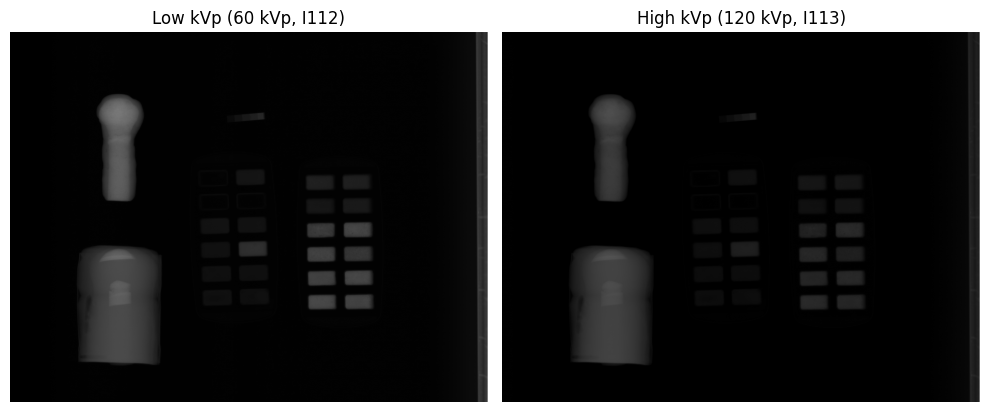

In [2]:
# ========================================================================================================

# Phase 1: Import Images

"""Scans of 21 October 2026. Every frame holds both ice trays (red on the left, blue on the right) with the PLA step wedge
above them, the plan B phantom (upper left) and the final phantom (lower left). The file names hold the preset (kVp, mA,
pixel size), the instance number and '_water' once the water cell (red tray, top right) was filled. Scans tagged with SKIP
are left out (open background clipped)."""

image_folder = '../Lodox Statscan Images/Scans'
name_prefix = '2026-10-21_trays-phantoms_'
SKIP = ('bg-saturated',)
pixel_spacing = 0.24            # mm, common pixel spacing for all scans

files = sorted(f for f in os.listdir(image_folder) if f.lower().endswith('.dcm') and not any(s in f for s in SKIP))
scans = {f[len(name_prefix):-4]: pydicom.dcmread(os.path.join(image_folder, f)) for f in files}
scans = dict(sorted(scans.items(), key=lambda item: float(item[1].KVP)))      # lowest to highest kVp
presets = list(scans)
for p, ds in scans.items():
    print(f"{p:35s} {float(ds.KVP):4.0f} kVp  {float(ds.XRayTubeCurrent):4.0f} mA  {float(ds.ImagerPixelSpacing[0]):.2f} mm")

"""The scans are not all the same size. The 70 kVp scan (I110, Humerus preset) is captured at 0.12 mm pixel spacing while the
rest are at 0.24 mm, and the number of rows can differ between scans because the scan length varies. Images must be the same
size to be compared pixel for pixel, so every scan is brought to the same pixel spacing and then cropped to a common shape."""

# Function to bring a scan to the common pixel spacing by averaging blocks of pixels
def match_spacing(image, spacing):
    data_set = image.pixel_array.astype(float)
    data_set[:, -1] = data_set[:, -2]       # the last column is a marker at the preset's maximum grey level, not image data
    factor = int(round(spacing / float(image.ImagerPixelSpacing[0])))     # e.g. 0.24 / 0.12 = 2 for I110 (rest are 1)
    return Affine_matrix.downsample(data_set, factor)

images = {p: match_spacing(scans[p], pixel_spacing) for p in presets}

# Crop all scans to the smallest shape. Every scan starts at the top, so the objects sit at nearly the same rows in each
# and only excess background at the bottom/right is removed.
rows = min(img.shape[0] for img in images.values())
cols = min(img.shape[1] for img in images.values())
images = {p: img[:rows, :cols] for p, img in images.items()}


# Function to repeat normalizing image
def ready_img(data_set):
    if data_set.ndim == 3:
        data_set = data_set[..., 0]  # to ensure the image dimensions are only 2D
    return (data_set - data_set.min()) / (data_set.max() - data_set.min())

# Preset pair to register and process: the water scans at 60 and 120 kVp (the water cell is the reference for R in Phase 4)
low_preset = '060kVp_080mA_0.24mm_I112_water'
high_preset = '120kVp_080mA_0.24mm_I113_water'

target = ready_img(images[low_preset])
misaligned = ready_img(images[high_preset])

output_folder = os.path.join('./outputs', f'I{scans[low_preset].InstanceNumber}_I{scans[high_preset].InstanceNumber}')
os.makedirs(output_folder, exist_ok=True)


# Display initial images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(target, cmap="gray")
axes[0].set_title(f"Low kVp ({scans[low_preset].KVP} kVp, I{scans[low_preset].InstanceNumber})")
axes[1].imshow(misaligned, cmap="gray")
axes[1].set_title(f"High kVp ({scans[high_preset].KVP} kVp, I{scans[high_preset].InstanceNumber})")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Pre-Processing

Despite the aim of thesis being to use the developed phantom for bone suppression, one cannot simply assume the phantom will not move
between subsequent scans. This could be due to the phantom being manually moved, slight shifts caused by bumping into the scanner or simply
as a result of the scanner's vibrations.

Every frame holds three groups of objects in fixed places: the ice trays with the step wedge above them, the
plan B phantom and the final phantom. Each group gets a fixed box (Modules/Regions.py) and is processed on its own from here on.
The objects are found with Otsu thresholding (Modules/Segmentation.py) of the smoothed target. With the phantoms and bone cells
in the frame, one Otsu split only separates those dense objects, so the split is repeated on the pixels below it (passes=2),
which separates the fat/muscle cells and the thin wedge steps from the background. Each box is then checked: the trays box must
hold 20 tray cells (21 with water) and the wedge, each phantom box one phantom. An object cut by the box edge is dropped, so an
object that has moved out of its box stops the pipeline here instead of giving wrong measurements.

Otsu threshold: 0.039 (normalised intensity); boxes checked: Trays, Plan B phantom, Final phantom


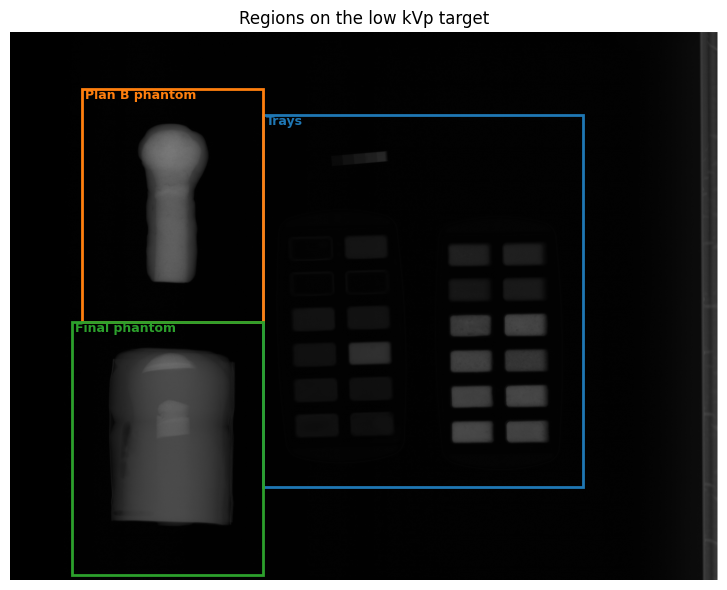

Trays: rotated 0.035 degrees, shifted (-0.12, 1.23) px, MSE 6.39e-04


Plan B phantom: rotated 0.000 degrees, shifted (0.00, 1.00) px, MSE 2.57e-03


Final phantom: rotated 0.000 degrees, shifted (0.00, 1.56) px, MSE 4.53e-04


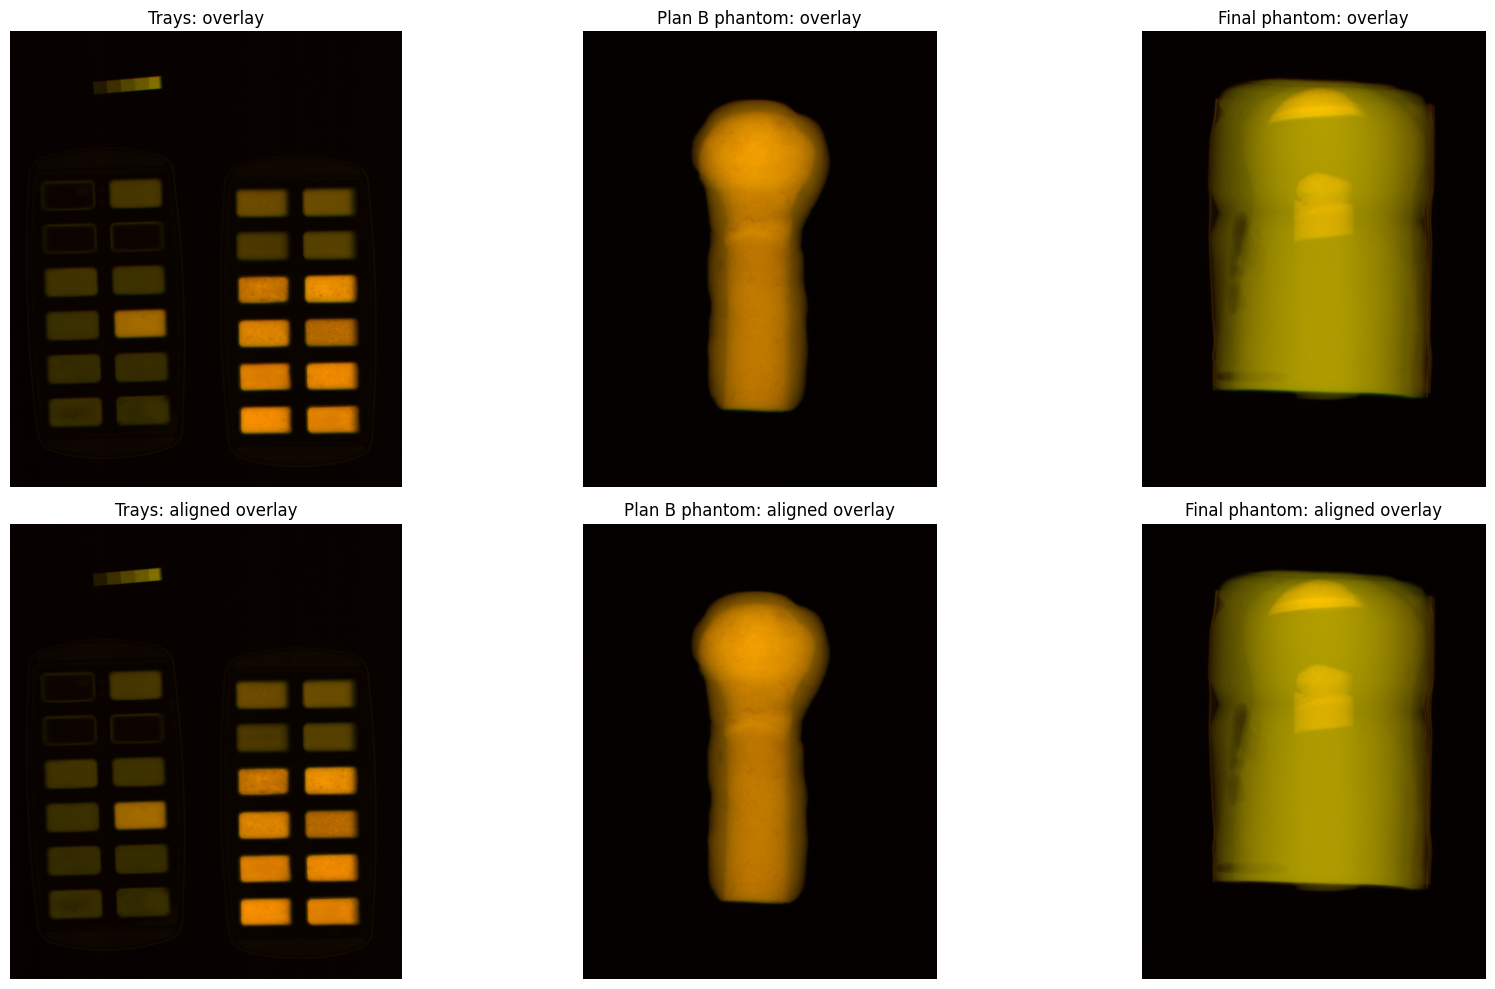

In [3]:
# ========================================================================================================

# Phase 2: Pre-processing


threshold = Segmentation.otsu_threshold(Segmentation.smooth(target, pixel_spacing), passes=2)
regions = Regions.split(target, threshold, pixel_spacing)
print(f"Otsu threshold: {threshold:.3f} (normalised intensity); boxes checked: {', '.join(regions)}")

fig, ax = plt.subplots(figsize=(8, 6))
Regions.show_regions(target, regions, pixel_spacing, ax=ax, title='Regions on the low kVp target')
plt.tight_layout()
plt.show()

"""Despite the aim of thesis being to use the developed phantom for bone suppression, one cannot simply assume the phantom will not move
between subsequent scans. This could be due to the phantom being manually moved, slight shifts caused by bumping into the scanner or simply
as a result of the scanner's vibrations. Therefore it is important to align the images before any further processing. This is done by
finding the optimal transformation parameters that minimize the mean squared error (MSE) between the target and misaligned images.
Each region is registered on its own: the trays were handled between scans (the water cell was filled before I112), so the trays and
the phantoms need not have moved by the same amount. The box leaves about 30 mm around each object, so the object stays inside it
in the misaligned image."""

# Affine_matrix.mse is the 'fun' minimised by scipy's minimize (Powell): mse is used as the similarity metric.
# The search runs on 4x downsampled images first (fast) and is then refined at full resolution.
targets, aligned, affine_matrices = {}, {}, {}
for name, region in regions.items():
    targets[name] = region.crop(target)
    moving = region.crop(misaligned)
    x0 = [0, 0, 0]                      # initial guess for [theta, tx, ty]
    (theta_opt, tx_opt, ty_opt), result = Affine_matrix.register(targets[name], moving, x0)

    # Affine transformation matrix ([row, col, 1] of the aligned crop -> misaligned crop) and the aligned crop
    affine_matrices[name] = Affine_matrix.affine_matrix(theta_opt, tx_opt, ty_opt, targets[name].shape)
    aligned[name] = Affine_matrix.transformation(moving, theta_opt, tx_opt, ty_opt)
    print(f"{name}: rotated {theta_opt:.3f} degrees, shifted ({tx_opt:.2f}, {ty_opt:.2f}) px, MSE {result.fun:.2e}")

# Show the overlays before (top) and after (bottom) registration
fig, axes = plt.subplots(2, len(regions), figsize=(6 * len(regions), 10))
for k, (name, region) in enumerate(regions.items()):
    before = np.stack([targets[name], region.crop(misaligned), np.zeros_like(targets[name])], axis=-1)
    after = np.stack([targets[name], aligned[name], np.zeros_like(targets[name])], axis=-1)
    for ax, overlay, title in [(axes[0, k], before, 'overlay'), (axes[1, k], after, 'aligned overlay')]:
        ax.imshow(np.clip(overlay / overlay.max(), 0, 1))
        ax.set_title(f'{name}: {title}')
        ax.axis('off')
plt.tight_layout()
plt.show()

## Region of Interest

Otsu thresholding was used previously to identify the different structures and the step wedge which is present in every image for the reference wedge calibration in the following sections. The ROIs are saved in arrays for processing later.

Red tray: rotated 1.5 degrees, cell pitch 53.1 x 34.3 mm, grid residual 0.9 px
Blue tray: rotated 0.6 degrees, cell pitch 53.0 x 34.3 mm, grid residual 2.0 px
Water cell: Red 1R; empty cells: Red 1L, Red 2L, Red 2R


Wedge: 53.0 mm long, 10.9 mm wide, thin end on the left


Estimated fat layer thickness: 2.9 mm (pass fat_thickness_mm to override)
Plan B phantom: bone 148 mm long, shaft 107 mm long and 31.6 mm wide


Final phantom: bone threshold 0.0311 above the column trend (5 x its robust standard deviation)


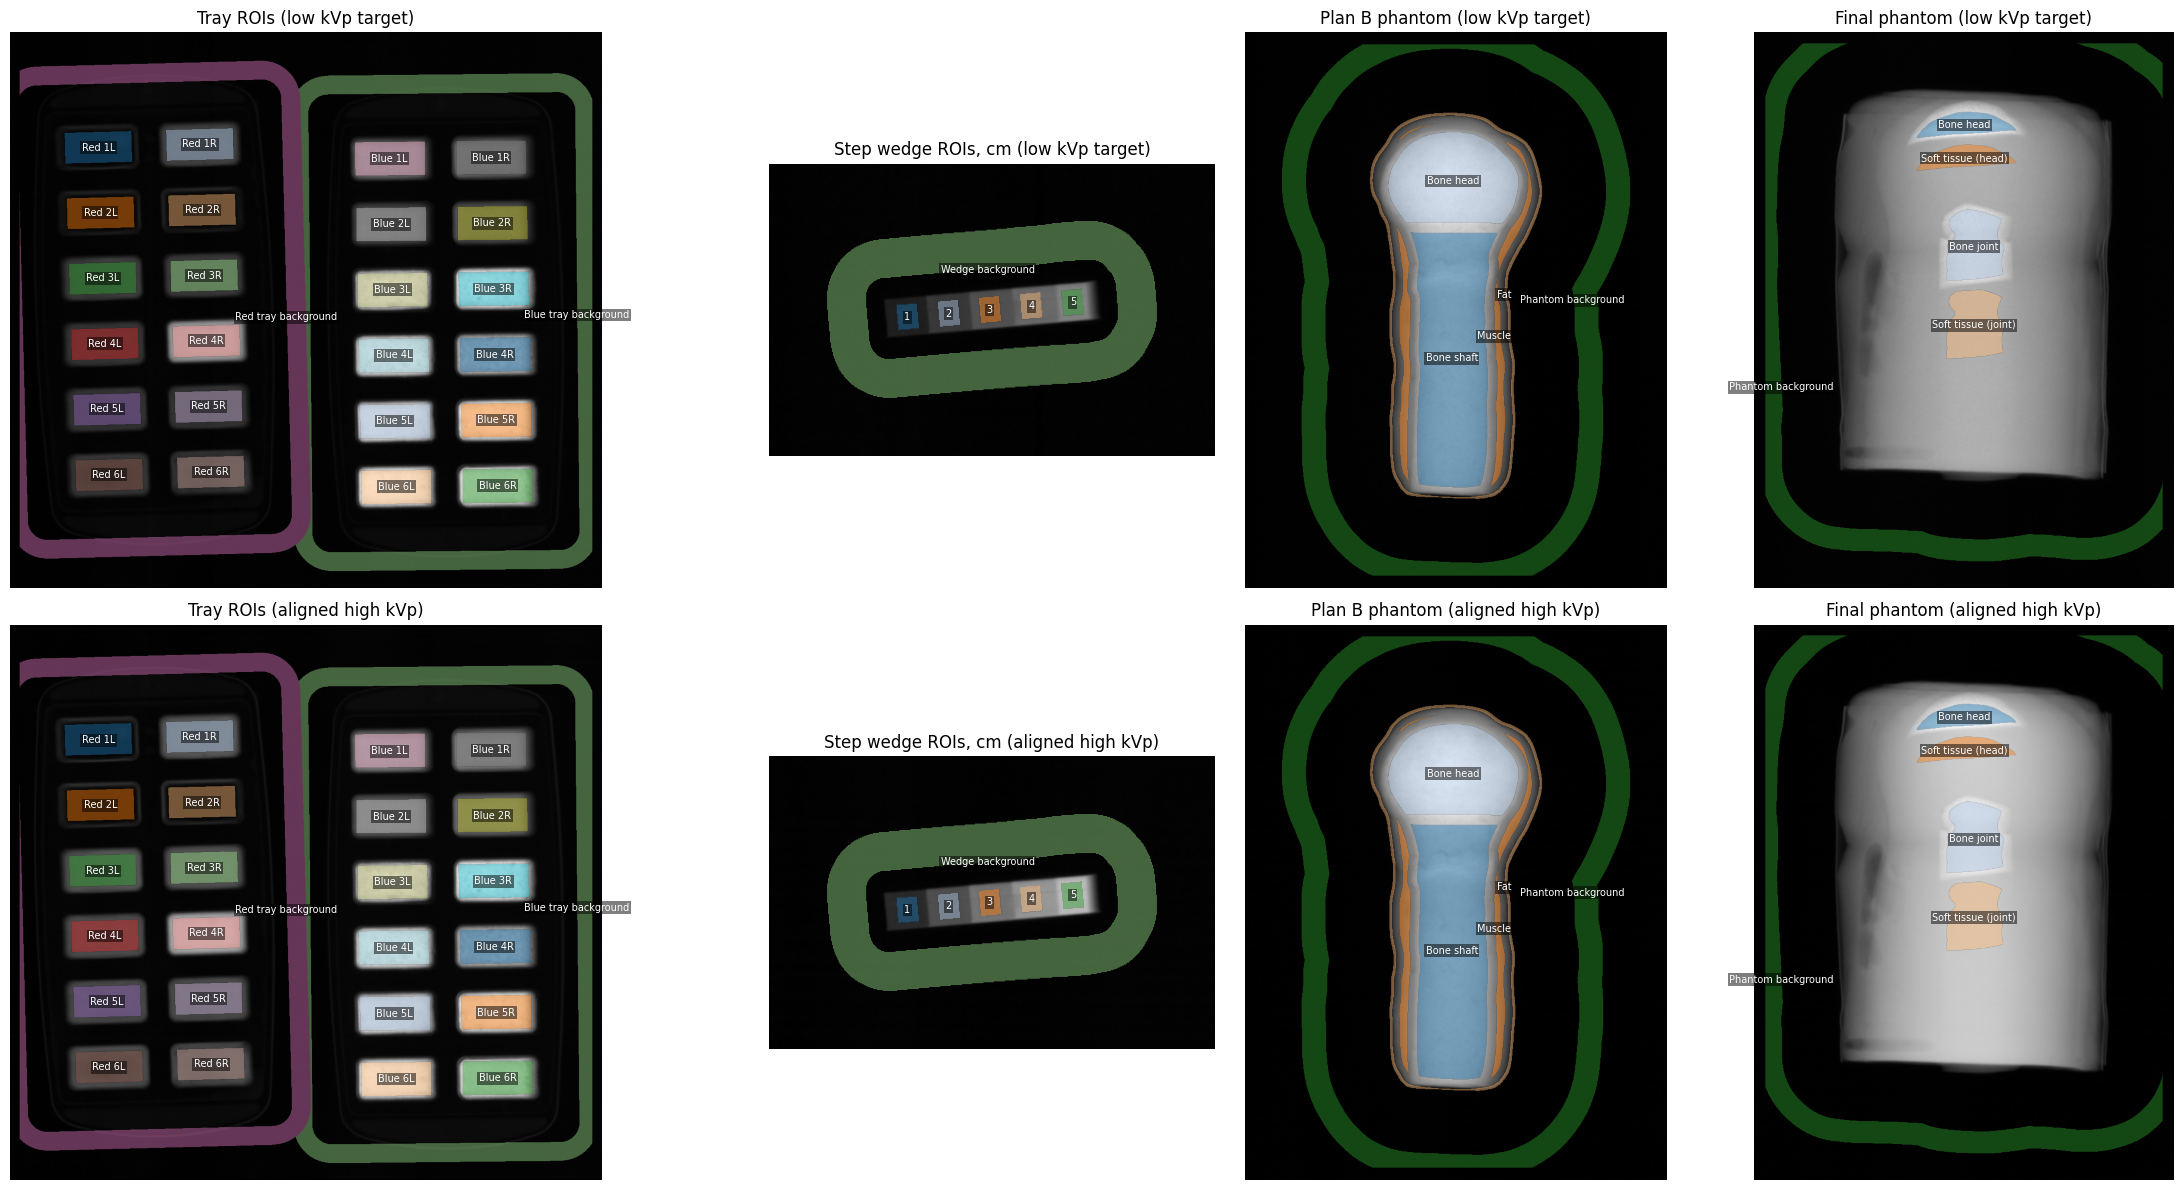

In [4]:
# ========================================================================================================

# Phase 3: Region of Interest

"""The masks are found on the target (low kVp) crop of each region; the high kVp crop was registered onto it in Phase 2, so the
same masks line up with the aligned crop.
* Trays: the filled cells are found from the Otsu objects, grouped into the red and blue tray, a 2 x 6 grid is fitted to each
  tray and every cell gets an ROI 3 mm inside its edges (the cell walls slope), plus a background band per tray. The water cell
  is recognised when it is filled. The step wedge gets one ROI per step and a background band.
* Plan B phantom: bone (eggshell + PoP + water 1:1:2.5) split into the shaft and the head where it widens, a thin silicone
  putty muscle layer around it and a candle-wax fat layer a few mm thick (estimated from the image).
* Final phantom: the CaCO3 settled at the head and the head-shaft joint, so bone ROIs are only placed there, each with a
  soft-tissue reference in the same image columns (same path length through the cylinder)."""

trays = Ice_tray_mask.Trays(targets['Trays'], regions['Trays'].labels, regions['Trays'].objects, pixel_spacing)
for name, tray in trays.trays.items():
    print(f"{name.capitalize()} tray: rotated {tray.rotation_deg:.1f} degrees, cell pitch {tray.pitch_mm[0]:.1f} x "
          f"{tray.pitch_mm[1]:.1f} mm, grid residual {tray.residual_px:.1f} px")

# Print which cells are empty as this would not count towards the trays mean
print(f"Water cell: {trays.water_cell or 'not filled in this scan'}; empty cells: {', '.join(trays.empty_cells)}")

wedge = Wedge_mask.Wedge_Mask(targets['Trays'], regions['Trays'].labels, regions['Trays'].objects, pixel_spacing)
print(f"Wedge: {wedge.length_mm:.1f} mm long, {wedge.width_mm:.1f} mm wide, thin end on the {wedge.thin_end}")

plan_b = Phantom_mask.Phantom_Mask(targets['Plan B phantom'], regions['Plan B phantom'].labels,
                                   regions['Plan B phantom'].objects, pixel_spacing, soft_tissue=True)
print(f"Plan B phantom: bone {plan_b.bone_length_mm:.0f} mm long, shaft {plan_b.shaft_length_mm:.0f} mm long "
      f"and {plan_b.shaft_width_mm:.1f} mm wide")

final = Phantom_mask.Final_Phantom_Mask(targets['Final phantom'], regions['Final phantom'].labels,
                                        regions['Final phantom'].objects, pixel_spacing)
print(f"Final phantom: bone threshold {final.bone_threshold:.4f} above the column trend "
      f"({final.bone_threshold / final.residual_sigma:.0f} x its robust standard deviation)")

# ROI validation (flowchart): the checks inside each mask class must pass before the ROIs are used
masks = {'Trays': [trays, wedge], 'Plan B phantom': [plan_b], 'Final phantom': [final]}
for name, region_masks in masks.items():
    if not all(m.valid for m in region_masks):
        print(f"ROI validation failed for {name}: check the overlays below before using these ROIs")

# Print masks over the target and aligned crops
fig, axes = plt.subplots(2, 4, figsize=(24, 12), gridspec_kw={'width_ratios': [2, 1, 1, 1.2]})
for row, (images_, label) in enumerate([(targets, 'low kVp target'), (aligned, 'aligned high kVp')]):
    trays.show(images_['Trays'], ax=axes[row, 0], title=f'Tray ROIs ({label})')
    wedge.show(images_['Trays'], ax=axes[row, 1], title=f'Step wedge ROIs, cm ({label})')
    plan_b.show(images_['Plan B phantom'], ax=axes[row, 2], title=f'Plan B phantom ({label})')
    final.show(images_['Final phantom'], ax=axes[row, 3], title=f'Final phantom ({label})')
plt.tight_layout()
plt.show()

# Save the ROIs of each region for processing later: one label array (0 = no ROI, k = roi_names[k - 1]) + the pixel values
# of every ROI in the low kVp target and the aligned high kVp crop
roi_values = {}
for name, region_masks in masks.items():
    roi_mask, roi_names = Segmentation.combine_masks(region_masks)
    roi_values[name] = {}
    for k, roi_name in enumerate(roi_names, start=1):
        roi = roi_mask == k
        roi_values[name][roi_name] = {'low': targets[name][roi], 'high': aligned[name][roi]}
    np.savez_compressed(os.path.join(output_folder, f"roi_mask_{name.replace(' ', '_')}.npz"), roi_mask=roi_mask,
                        roi_names=np.array(roi_names), box_mm=np.array(regions[name].box_mm))

# for name, values in roi_values.items():
#     print(f"\n{name}\n{'ROI':22s} {'pixels':>7s}   {'low kVp':>15s}   {'high kVp':>15s}")
#     for roi_name, v in values.items():
#         if v['low'].size == 0:
#             print(f"{roi_name:22s} {'empty':>7s}")
#             continue
#         print(f"{roi_name:22s} {v['low'].size:7d}   {v['low'].mean():.3f} ± {v['low'].std():.3f}   "
#               f"{v['high'].mean():.3f} ± {v['high'].std():.3f}   {trays.layout.get(roi_name, '')}")

## Wedge Calibration

Due to grey-scale levels or in some scans, filtering effects being present affecting direct comparison between presets, a step wedge is made present in each image as a common refrence point in addition to water whose attenuation value is known. By treating beam hardening, scattering and the effects of filtering as an increasing function, f, the step wedge and water can be used  to determine the total attenuation along the ray $A = f(\mu \cdot d)$. This equation is applied to the PLA step wedge to form equation 4.1, to the cells in the ice tray experiment to form equation 4.2 and to the water cell to form equation 4.3. Relating them all gives us an approximated attenuation, R, to the linear attenuation of a cell of material and water by the equation $R = \frac{\mu_{cell}}{\mu_{water}}$

Low kVp (60 kVp): C(t) = 0.03126 t + -0.0005794 t^2 (rms residual 0.001); straight line C = 0.02889 t (rms residual 0.0022); rises across 0-5 cm
    Step 1 cm: contrast C = 0.0324, t_eq = 1.056 cm
    Step 2 cm: contrast C = 0.0604, t_eq = 2.006 cm
    Step 3 cm: contrast C = 0.0880, t_eq = 2.981 cm
    Step 4 cm: contrast C = 0.1146, t_eq = 3.957 cm
    Step 5 cm: contrast C = 0.1427, t_eq = 5.033 cm
High kVp (120 kVp): C(t) = 0.02694 t + -0.0003408 t^2 (rms residual 0.00037); straight line C = 0.02554 t (rms residual 0.0012); rises across 0-5 cm
    Step 1 cm: contrast C = 0.0271, t_eq = 1.018 cm
    Step 2 cm: contrast C = 0.0527, t_eq = 2.009 cm
    Step 3 cm: contrast C = 0.0775, t_eq = 2.992 cm
    Step 4 cm: contrast C = 0.1018, t_eq = 3.979 cm
    Step 5 cm: contrast C = 0.1265, t_eq = 5.015 cm


,contents,R (low),R_source (low),R_wedge (low),R_beer_lambert (low),t_eq_cm (low),R (high),R_source (high),R_wedge (high),R_beer_lambert (high),t_eq_cm (high)
ROI,,,,,,,,,,,
Red 3L,Resin,0.871,wedge,0.871,0.876,2.135,0.935,wedge,0.935,0.937,2.167
Red 3R,Resin + red food colouring,0.845,wedge,0.845,0.851,2.077,0.913,wedge,0.913,0.915,2.119
Red 4L,Candle wax,0.771,wedge,0.771,0.778,1.906,0.876,wedge,0.876,0.879,2.036
Red 4R,Silicone putty,2.523,Beer-Lambert,NaN,2.523,NaN,2.079,wedge,2.079,2.014,4.685
Red 5L,Coconut oil + beeswax (1:1),0.694,wedge,0.694,0.704,1.733,0.776,wedge,0.776,0.781,1.817
Red 5R,Beeswax + coconut oil (2:1),0.707,wedge,0.707,0.716,1.762,0.800,wedge,0.800,0.805,1.870
Red 6L,Coconut oil,0.693,wedge,0.693,0.702,1.729,0.764,wedge,0.764,0.769,1.790
Red 6R,Beeswax,0.664,wedge,0.664,0.674,1.663,0.772,wedge,0.772,0.777,1.809
Red 1R,Water reference,1.000,wedge,1.000,1.000,2.429,1.000,wedge,1.000,1.000,2.310


The blue tray has no empty cells: it uses the floor of the red tray's empty cells (assumes the same floor)


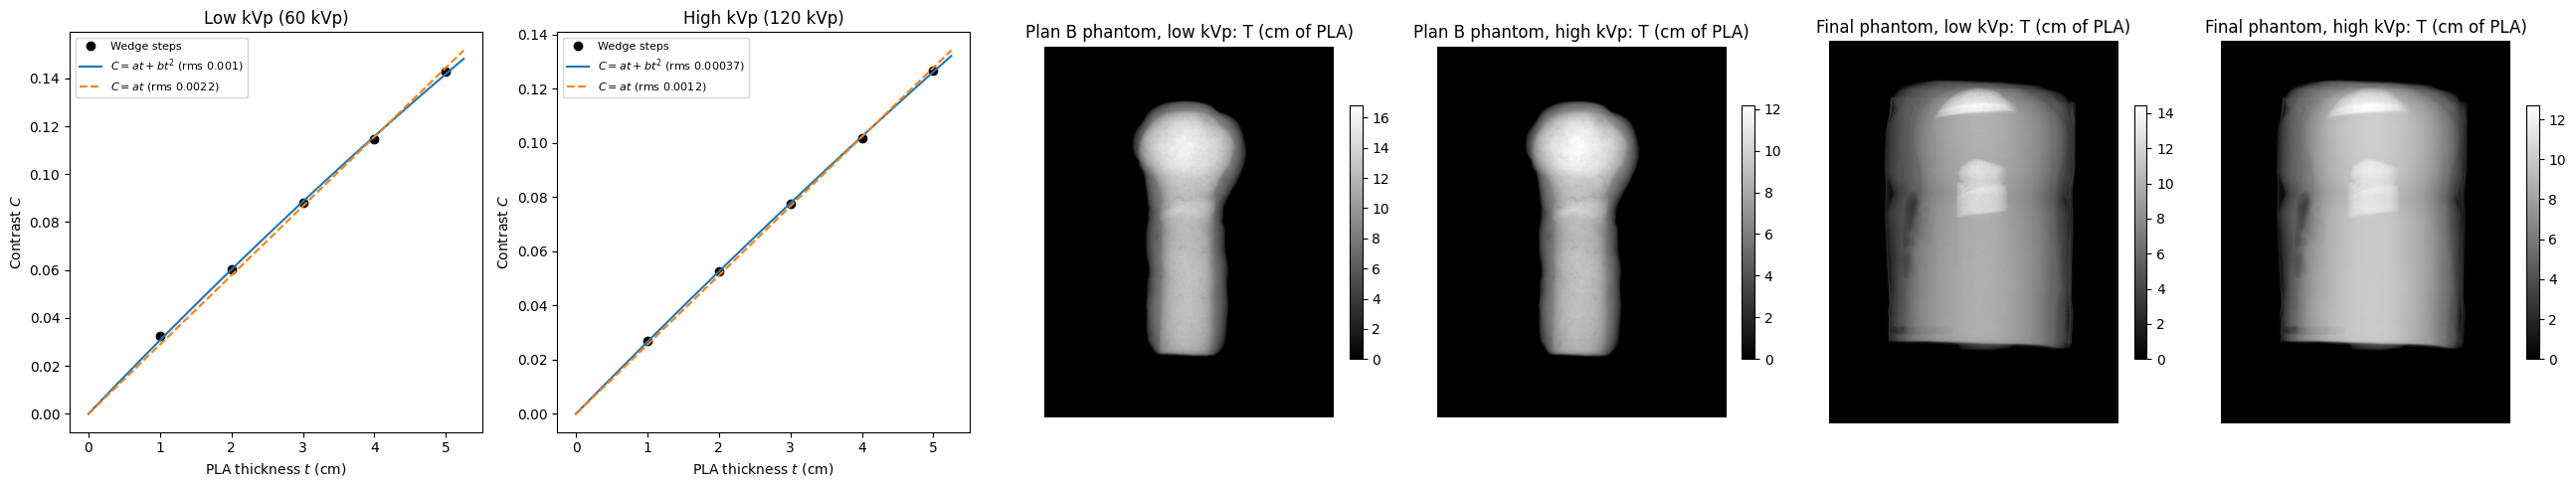

In [5]:
# ========================================================================================================

# Phase 4: Wedge Calibration

"""The wedge calibration (Modules/Wedge_calibration.py) follows the Wedge Calibration section of the Implementation chapter.
The median grey-level of each wedge step and of the wedge background band gives the contrast of step k, C_k = g_k - g_bg with
t_k = k cm. The five points are fitted by least squares with a quadratic through the origin, C(t) = a t + b t^2 (zero PLA gives
zero contrast), and a straight line C = a t is fitted alongside it to show what the quadratic term adds. The inverse,
t_eq(C) = 2C / (a + sqrt(a^2 + 4bC)), converts any contrast to a PLA-equivalent thickness. It is only trusted inside the wedge
range (0-5 cm), and the fit only if it rises across that range (a + 10b > 0); contrasts beyond it are not extrapolated, because
the quadratic bends over and overestimates the thickness there. The wedge is in the trays box; one calibration per preset holds
for the whole frame."""

calibration = {
    'low': Wedge_calibration.Wedge_Calibration(targets['Trays'], wedge, f'Low kVp ({scans[low_preset].KVP} kVp)'),
    'high': Wedge_calibration.Wedge_Calibration(aligned['Trays'], wedge, f'High kVp ({scans[high_preset].KVP} kVp)'),
}
for cal in calibration.values():
    print(cal.summary())
    for t, c in zip(cal.t, cal.contrast):
        print(f"    Step {t:g} cm: contrast C = {c:.4f}, t_eq = {cal.thickness(c):.3f} cm")

"""Ice trays: every filled cell becomes a PLA-equivalent thickness, the tray floor (empty cells) is subtracted, and
R = mu_cell / mu_water with the water cell of the same image (equal 28 mm fill depths). Most plaster-of-Paris bone cells are
thicker than the wedge (6-10 cm of PLA), so they take R from Beer-Lambert instead: the images are unfiltered log images, so
R is the ratio of the floor-subtracted contrasts of the cell and the water cell. Both values are kept for every cell inside the
wedge range, where they agree to about 0.01."""

cell_results = {k: Wedge_calibration.relative_attenuation(calibration[k], img['Trays'], trays)
                for k, img in [('low', targets), ('high', aligned)]}
columns = ['R', 'R_source', 'R_wedge', 'R_beer_lambert', 't_eq_cm']
table = cell_results['low'][['contents'] + columns].join(cell_results['high'][columns], lsuffix=' (low)', rsuffix=' (high)')
display(table.round(3))
if trays.water_cell is None:
    print("No water cell in this scan: R cannot be computed, mu/mu_PLA is still given")
if 'other tray' in set(cell_results['low']['floor_from']):
    print("The blue tray has no empty cells: it uses the floor of the red tray's empty cells (assumes the same floor)")
table.to_csv(os.path.join(output_folder, 'tray_attenuation.csv'))

"""Phantoms: thickness maps T_L and T_H in cm of PLA for the subtraction stage. The phantoms are thicker than the wedge, so the
maps use the straight-line gain, T = (image - background) / a, with the background band next to each phantom. This puts both
presets on a common scale, so the subtraction weight w found by the sweep can be compared with the value predicted from theory
(cast bone composition and PLA)."""

thickness_maps = {}
for name, mask in [('Plan B phantom', plan_b), ('Final phantom', final)]:
    thickness_maps[name] = {
        k: calibration[k].linear_thickness_map(img[name], np.median(img[name][mask.roi('Phantom background')]))
        for k, img in [('low', targets), ('high', aligned)]}
np.savez_compressed(os.path.join(output_folder, 'thickness_maps.npz'),
                    **{f"{name.replace(' ', '_')}_{k}": T for name, maps in thickness_maps.items() for k, T in maps.items()},
                    gain_low=calibration['low'].a_linear, gain_high=calibration['high'].a_linear)

fig, axes = plt.subplots(1, 6, figsize=(26, 5), gridspec_kw={'width_ratios': [1.3, 1.3, 1, 1, 1, 1]})
calibration['low'].show(axes[0])
calibration['high'].show(axes[1])
for ax, (name, k) in zip(axes[2:], [(n, k) for n in thickness_maps for k in ('low', 'high')]):
    im = ax.imshow(thickness_maps[name][k], cmap='gray', vmin=0)
    ax.set_title(f"{name}, {k} kVp: T (cm of PLA)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

## Bone Suppression

Using the wedge theory outlined in the report to act as the common unit between the two presets, bone suppression is done by sweeping through $w$ values from 0 to $2w_{bone}$ and confirmed through Equation 3.3: $w_{wedge} = \frac{\mu_b(E_H)}{\mu_b(E_L)} \cdot \frac{\mu_{PLA}(E_L)}{\mu_{PLA}(E_H)}$

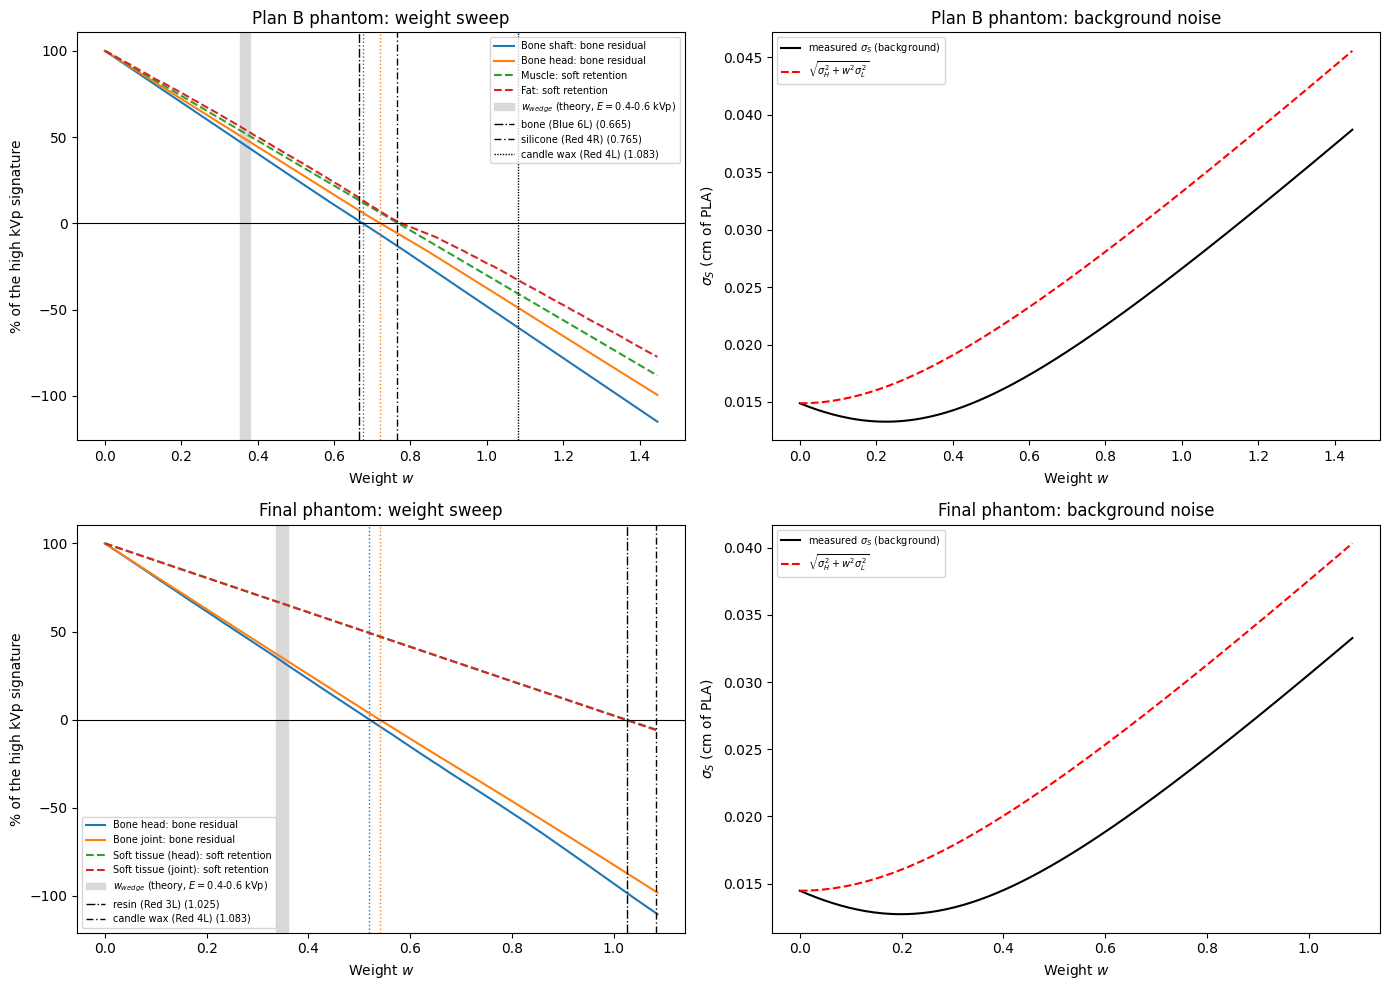

,phantom,b_L,b_H,w_bone,w_opt,soft_retention_pct,sigma_S,sigma_S_predicted,w_wedge_min,w_wedge_max,w tray bone (Blue 6L),w tray silicone (Red 4R),w tray candle wax (Red 4L),w tray resin (Red 3L)
ROI,,,,,,,,,,,,,,
Bone shaft,Plan B phantom,5.5579,3.7291,0.6710,0.6753,12.0776,0.0189,0.0250,0.3524,0.3807,0.6647,0.7654,1.0826,NaN
Bone head,Plan B phantom,7.5312,5.4468,0.7232,0.7214,6.0834,0.0199,0.0261,0.3524,0.3807,0.6647,0.7654,1.0826,NaN
Bone head,Final phantom,2.9600,1.5224,0.5143,0.5199,49.1249,0.0169,0.0231,0.3371,0.3592,NaN,NaN,1.0826,1.0253
Bone joint,Final phantom,2.3522,1.2773,0.5430,0.5398,47.1893,0.0174,0.0236,0.3371,0.3592,NaN,NaN,1.0826,1.0253


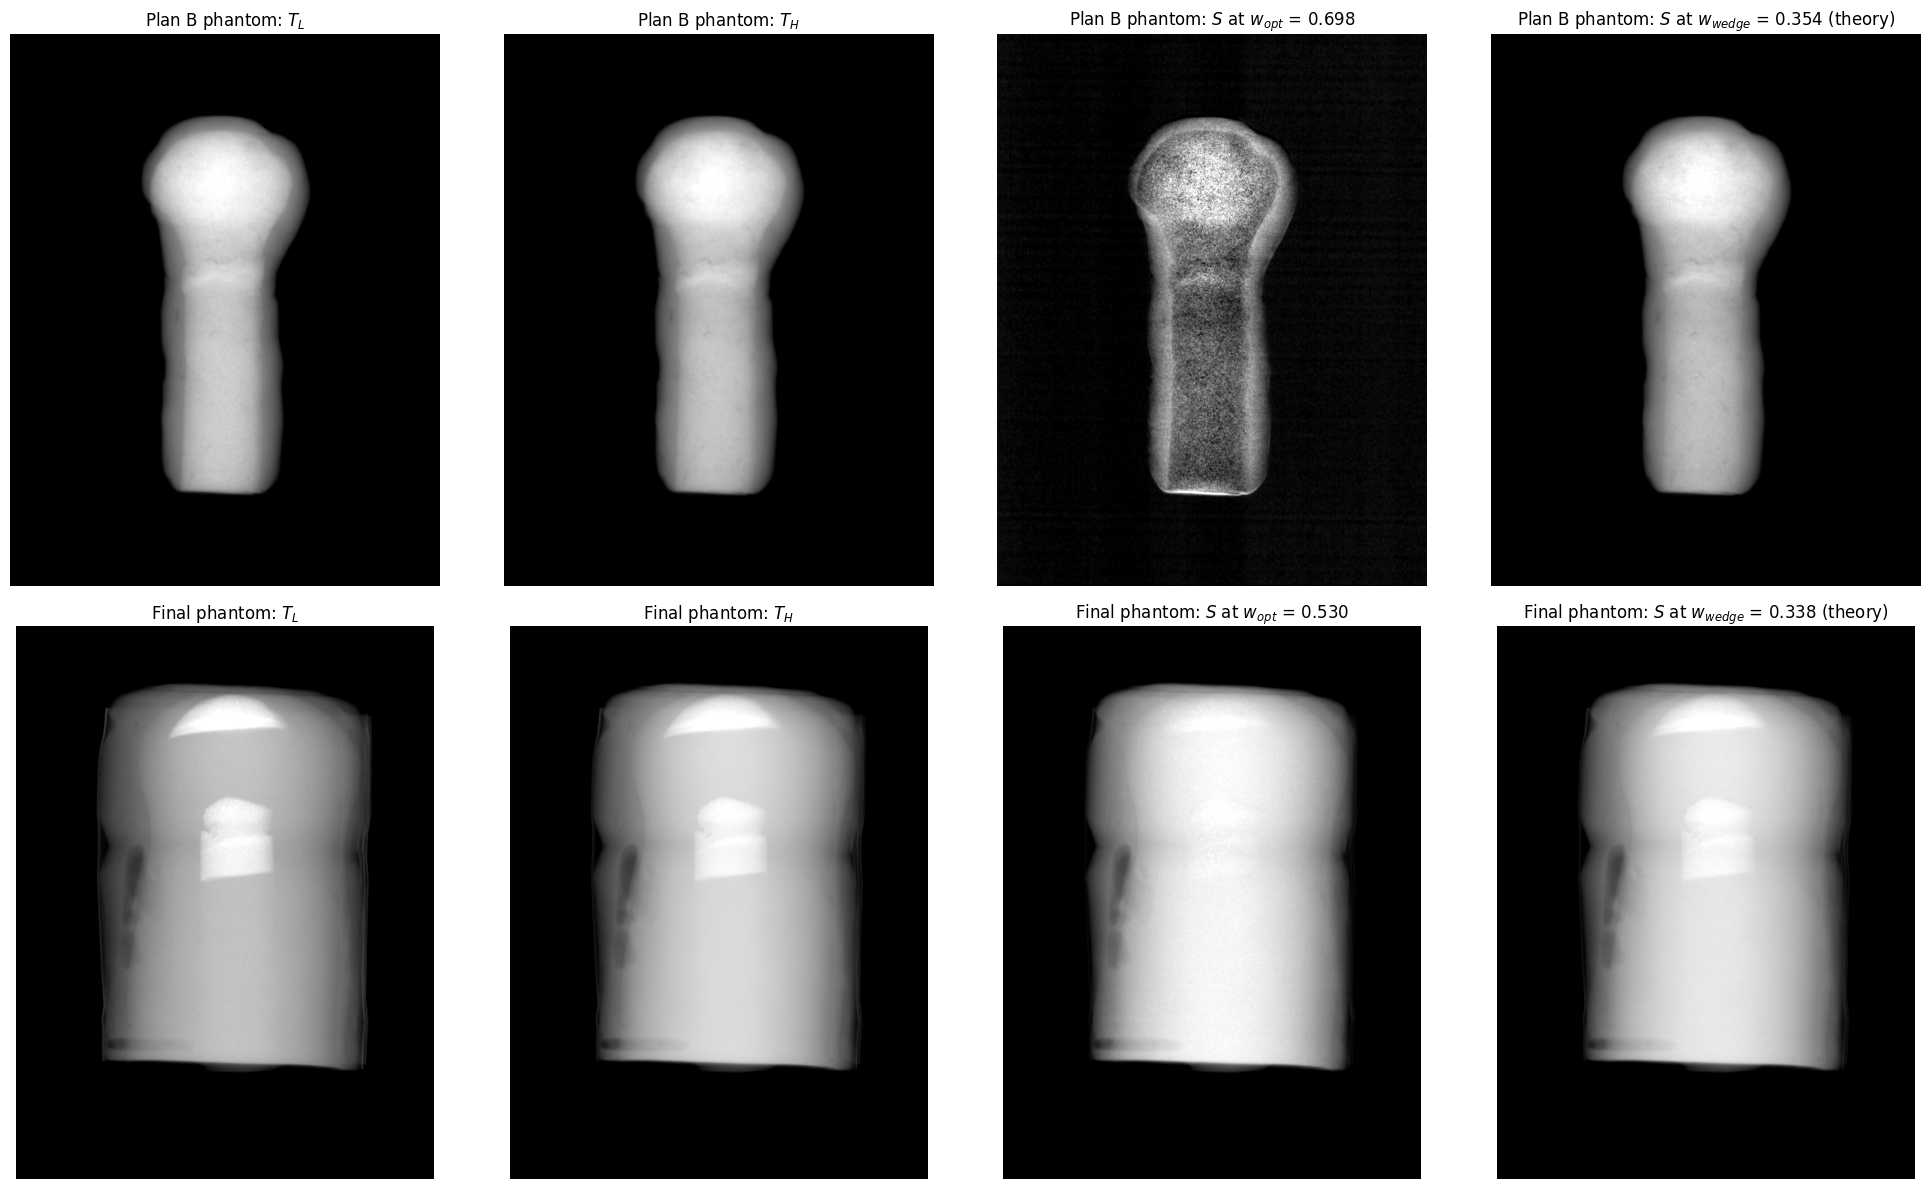

In [6]:
# ========================================================================================================

# Phase 5: Bone Suppression

"""Weighted log subtraction (Methodology chapter, Bone Suppression section; Modules/Bone_suppression.py) on the thickness maps
of Phase 4: S = T_H - w T_L (eq. 3.2).
Signatures (before subtraction, medians of T): bone signature b = bone ROI - its reference ROI, soft-tissue signature
s = soft-tissue ROI - background. w_bone = b_H / b_L.
Sweep: w from 0 to 2 w_bone in 201 steps (np.linspace, steps of 1 % of w_bone). At every w the bone residual, the soft retention
and the background noise of S are measured. w_opt, where the bone residual crosses zero, is interpolated between the two steps
either side of zero, so a finer grid gives smoother curves but the same w_opt.
* Plan B phantom: bone (eggshell + PoP + water 1:1:2.5, the same mixture as tray cell Blue 6L) against the silicone muscle
  around it, and the muscle and fat against the background. The bone sits on top of the silicone rather than replacing it, so
  its weight is close to that of the bone mixture itself. The wax layer is only a few mm thick and uneven, so the fat ROI
  also contains silicone.
* Final phantom: bone (the settled CaCO3) against the soft tissue in the same columns, and soft tissue against the background.
  Here the CaCO3 replaces resin along the same path, so the signature is CaCO3 minus resin.
Every material has its own cancelling weight, measured on its tray cell (vertical lines in the sweep plots). The soft tissue
kept at w_opt is roughly 1 - w_opt / w_soft, so the further the soft-tissue weight is from the bone weight, the more is kept.
Theory: w_wedge of eq. 3.3 for effective energies of 0.4-0.6 x kVp. The plan B bone uses its cured recipe. For the final phantom
the bone signature is the extra CaCO3 over the resin, so pure CaCO3 is used (the resin it displaces is left out)."""

kvp_low, kvp_high = float(scans[low_preset].KVP), float(scans[high_preset].KVP)
phantoms = {
    'Plan B phantom': dict(mask=plan_b, material='Eggshell + PoP + water (1:1:2.5)',
                           tray_cells={'bone': 'Blue 6L', 'silicone': 'Red 4R', 'candle wax': 'Red 4L'},
                           bones={'Bone shaft': 'Muscle', 'Bone head': 'Muscle'},
                           soft={'Muscle': 'Phantom background', 'Fat': 'Phantom background'}),
    'Final phantom': dict(mask=final, material='CaCO3', tray_cells={'resin': 'Red 3L', 'candle wax': 'Red 4L'},
                          bones={'Bone head': 'Soft tissue (head)', 'Bone joint': 'Soft tissue (joint)'},
                          soft={'Soft tissue (head)': 'Phantom background', 'Soft tissue (joint)': 'Phantom background'}),
}

sweeps, results = {}, []
fig, axes = plt.subplots(len(phantoms), 2, figsize=(14, 5 * len(phantoms)))
for (name, p), ax in zip(phantoms.items(), axes):
    T = thickness_maps[name]
    sweep = Bone_suppression.Weight_Sweep(T['low'], T['high'], p['mask'], p['bones'], p['soft'], label=name)

    # Theory band (eq. 3.3) and the weights measured on the tray cells of the phantom's materials
    f, w_theory = Bone_suppression.w_wedge(Bone_suppression.BONE_MATERIALS[p['material']], kvp_low, kvp_high)
    p['w_wedge'] = np.interp(0.5, f, w_theory)                  # E = 0.5 x kVp, the centre of the band
    marks = {f'{material} ({cell})': Bone_suppression.tray_weight(cell_results, calibration, cell)
             for material, cell in p['tray_cells'].items()}
    sweep.show(ax, theory=(w_theory.min(), w_theory.max()), marks=marks)

    df = sweep.summary()
    df.insert(0, 'phantom', name)
    df['w_wedge_min'], df['w_wedge_max'] = w_theory.min(), w_theory.max()
    for label, w in marks.items():
        df[f'w tray {label}'] = w
    results.append(df)
    sweeps[name] = sweep
plt.tight_layout()
plt.show()

results = pd.concat(results)
display(results.round(4))
results.to_csv(os.path.join(output_folder, 'weight_sweep.csv'))

# Subtracted images at w_opt (one weight per phantom: the mean w_opt of its bone ROIs) and at the theoretical w_wedge
# (E = 0.5 x kVp), next to T_L and T_H
suppressed = {}                                                 # {phantom: {'S': subtracted image, 'w': w_opt}}
fig, axes = plt.subplots(len(sweeps), 4, figsize=(20, 6 * len(sweeps)))
for row, (name, sweep) in zip(axes, sweeps.items()):
    w = np.nanmean(list(sweep.w_opt.values()))
    S = sweep.subtract(w)
    suppressed[name] = {'S': S, 'w': w}
    S_theory = sweep.subtract(phantoms[name]['w_wedge'])
    np.savez_compressed(os.path.join(output_folder, f"suppressed_{name.replace(' ', '_')}.npz"), S=S, w_opt=w,
                        S_theory=S_theory, w_wedge=phantoms[name]['w_wedge'])
    inside = phantoms[name]['mask'].footprint
    for ax, image, title in zip(row, [sweep.T_low, sweep.T_high, S, S_theory],
                                ['$T_L$', '$T_H$', f'$S$ at $w_{{opt}}$ = {w:.3f}',
                                 f"$S$ at $w_{{wedge}}$ = {phantoms[name]['w_wedge']:.3f} (theory)"]):
        vmin, vmax = np.percentile(image[inside], [1, 99])
        ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax)
        ax.set_title(f'{name}: {title}')
        ax.axis('off')
plt.tight_layout()
plt.show()

## Denoising

Image subtraction introduces its own noise into images affectin the SNR and CNR of the image. This section aims to apply classical and denoising filters to enhance the final bone suppressed images.

Plan B phantom: rho_x = 0.62, rho_y = 0.71 -> Noise2Noise
Final phantom: rho_x = 0.65, rho_y = 0.76 -> Noise2Noise


Trays, 060kVp_080mA_0.24mm_I106: rotated -0.608 degrees, shifted (-4.06, -9.37) px


Trays, 120kVp_080mA_0.24mm_I108: rotated -0.682 degrees, shifted (-5.07, 4.59) px


Plan B phantom, 060kVp_080mA_0.24mm_I106: rotated -0.000 degrees, shifted (-0.05, -13.10) px


Plan B phantom, 120kVp_080mA_0.24mm_I108: rotated -0.000 degrees, shifted (-0.03, -0.13) px


Final phantom, 060kVp_080mA_0.24mm_I106: rotated -0.001 degrees, shifted (-0.18, -13.11) px


Final phantom, 120kVp_080mA_0.24mm_I108: rotated -0.000 degrees, shifted (-0.11, 0.43) px


Noise2Noise network loaded from ./outputs\I112_I113\noise2noise.pt


max_abs_delta_mu  \
phantom        filter                                       
Plan B phantom Gaussian (light)                     0.010   
               Gaussian (medium)                    0.016   
               Gaussian (strong)                    0.020   
               Median (light)                       0.005   
               Median (medium)                      0.012   
               Median (strong)                      0.015   
               Bilateral (light)                    0.004   
               Bilateral (medium)                   0.016   
               Bilateral (strong)                   0.034   
               Non-local means (light)              0.001   
               Non-local means (medium)             0.001   
               Non-local means (strong)             0.003   
Final phantom  Gaussian (light)                     0.005   
               Gaussian (medium)                    0.008   
               Gaussian (strong)                    0.009   
               Median (light)                       0.003   
               Median (medium)                      0.005   
               Median (strong)                      0.007   
               Bilateral (light)                    0.005   
               Bilateral (medium)                   0.005   
               Bilateral (strong)                   0.004   
               Non-local means (light)              0.001   
               Non-local means (medium)             0.001   
               Non-local means (strong)             0.004   
Plan B phantom Noise2Noise                          0.015   
Final phantom  Noise2Noise                          0.006   

                                         noise_reduction_pct  edge_change_mm  \
phantom        filter                                                          
Plan B phantom Gaussian (light)                       19.534           0.051   
               Gaussian (medium)                      29.345           0.166   
               Gaussian (strong)                      36.034           0.564   
               Median (light)                         10.149          -0.010   
               Median (medium)                        18.955          -0.015   
               Median (strong)                        25.436          -0.016   
               Bilateral (light)                      22.658          -0.096   
               Bilateral (medium)                     31.077          -0.117   
               Bilateral (strong)                     36.348          -0.178   
               Non-local means (light)                34.301          -0.015   
               Non-local means (medium)               34.819          -0.022   
               Non-local means (strong)               35.392          -0.037   
Final phantom  Gaussian (light)                       17.401           0.031   
               Gaussian (medium)                      27.330           0.091   
               Gaussian (strong)                      34.652           0.134   
               Median (light)                          8.777          -0.002   
               Median (medium)                        17.109          -0.004   
               Median (strong)                        23.578          -0.008   
               Bilateral (light)                      19.119          -0.018   
               Bilateral (medium)                     27.640          -0.022   
               Bilateral (strong)                     33.352          -0.025   
               Non-local means (light)                32.487          -0.002   
               Non-local means (medium)               33.080          -0.002   
               Non-local means (strong)               33.789          -0.004   
Plan B phantom Noise2Noise                            29.414           0.055   
Final phantom  Noise2Noise                            27.883           0.049   

                                         delta CNR soft tissue / background (%)  
phantom  

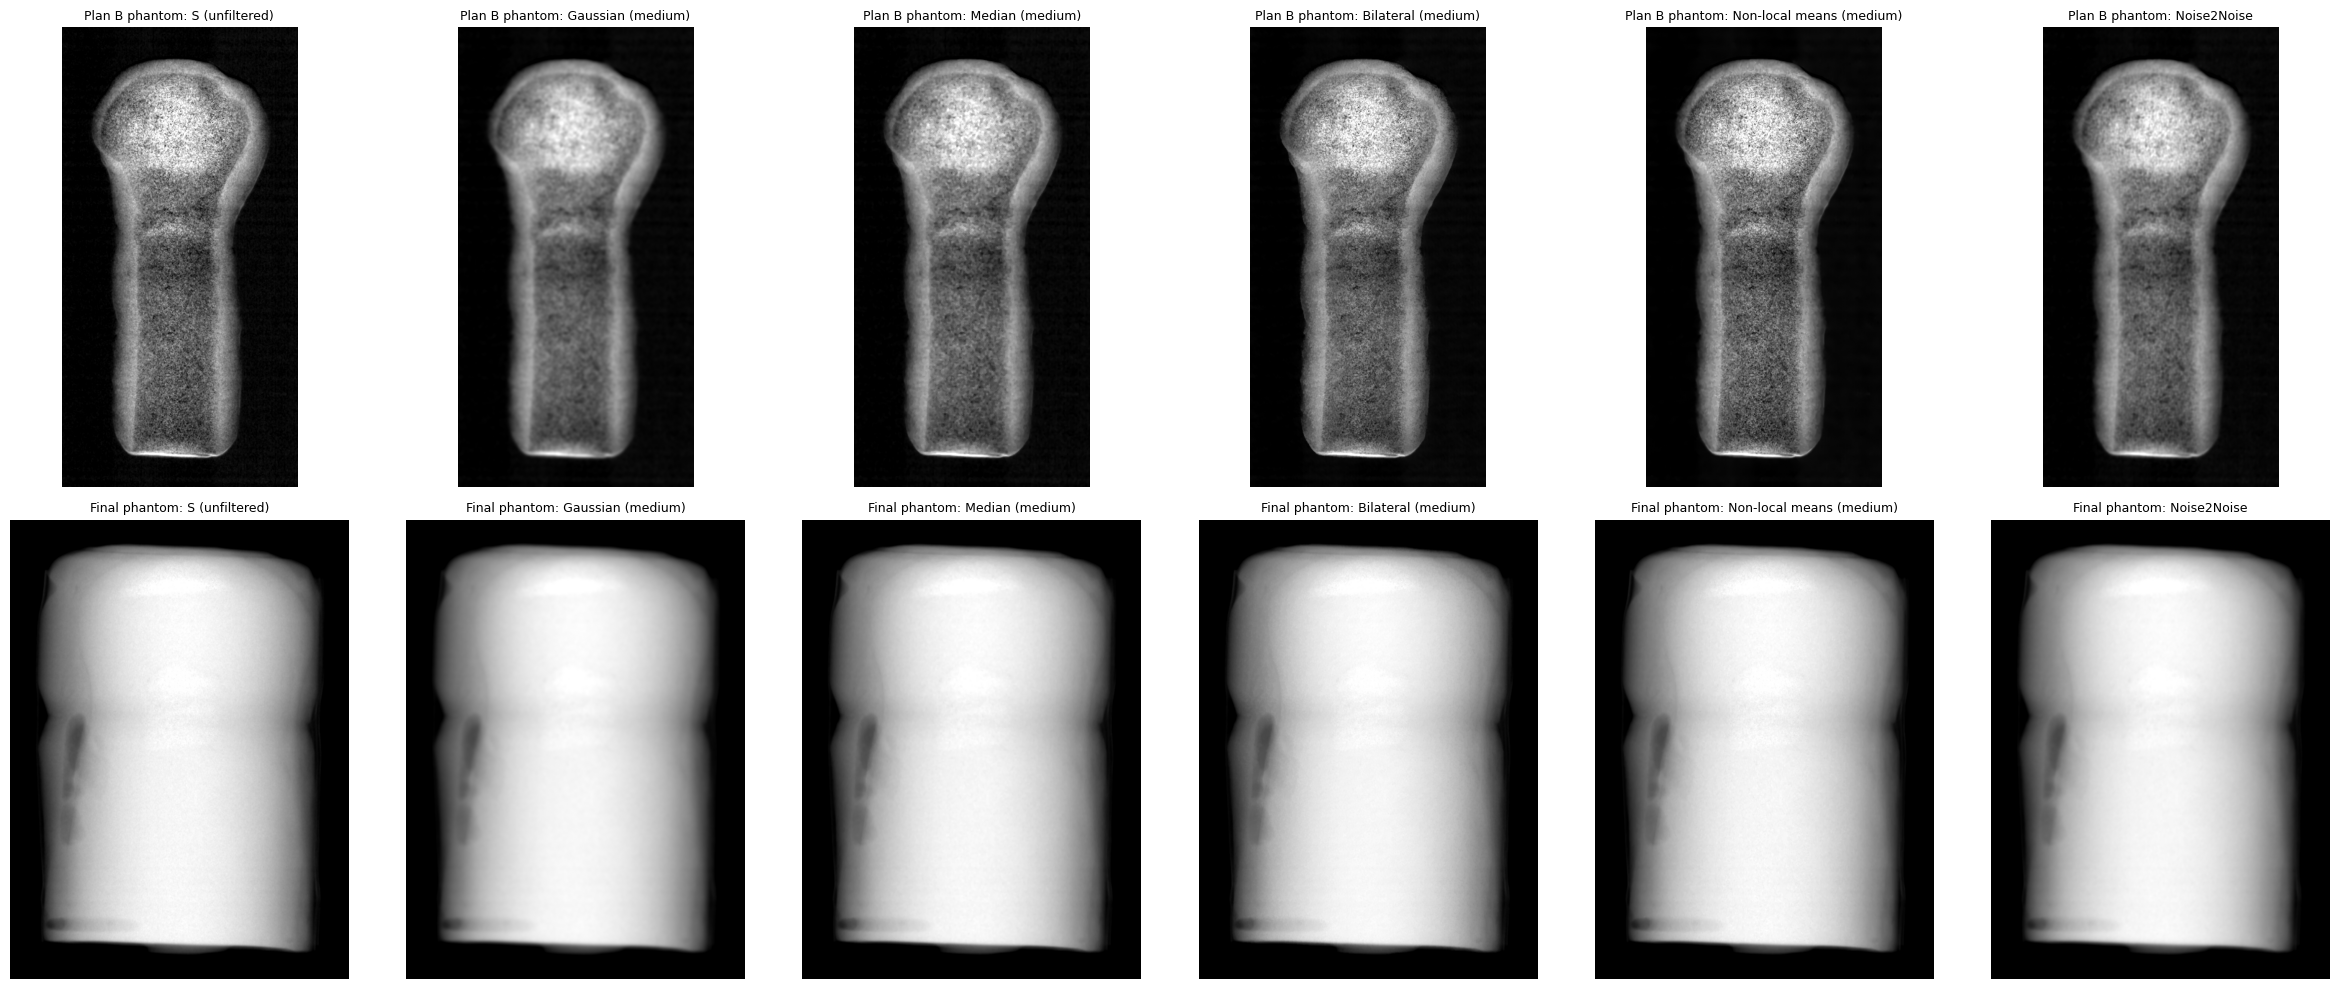

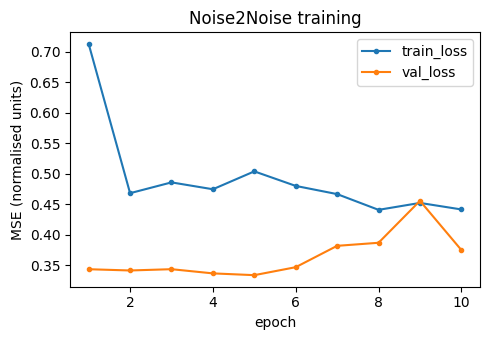

In [7]:
# ========================================================================================================

# Phase 6: Denoising

"""Noise suppression of the bone-suppressed images (Methodology chapter, Classical and Learning-Based Filter Selection;
Modules/Denoising.py). The input is the subtracted image S of each phantom at w_opt from Phase 5: it is kept in memory in
`suppressed` ({phantom: {'S': image, 'w': w_opt}}) and was also saved to outputs/.../suppressed_<phantom>.npz, which
np.load opens as a dictionary of arrays (e.g. np.load(path)['S']). The filters work on S in cm of PLA (floating point), so
the results can be measured with the same ROIs; converting to 8-bit RGB for OpenCV would round the values away.
Every filter is judged by: max |delta mu| (largest change of an ROI median, should be close to 0), the noise reduction in the
background band, delta CNR (%) of every ROI pair, and the change of the phantom's edge width (blur cost)."""

# 1. Noise model selection: lag-one autocorrelation of the noise residuals in the background band of S
for name, s in suppressed.items():
    rho_x, rho_y = Denoising.noise_autocorrelation(s['S'], phantoms[name]['mask'].roi('Phantom background'))
    print(f"{name}: rho_x = {rho_x:.2f}, rho_y = {rho_y:.2f} -> {Denoising.select_model(rho_x, rho_y)}")

# 2. Classical filters, each at three strengths (Modules/Denoising.py, FILTER_SETTINGS)
def phantom_metrics(name, image):
    mask, p = phantoms[name]['mask'], phantoms[name]
    pairs = list(p['bones'].items()) + list(p['soft'].items())
    return Denoising.image_metrics(image, mask.rois, pairs, 'Phantom background', mask.footprint, pixel_spacing)

original = {name: phantom_metrics(name, s['S']) for name, s in suppressed.items()}
denoised = {name: {} for name in suppressed}
rows = []
for name, s in suppressed.items():
    for f in Denoising.FILTER_SETTINGS:
        for level, level_name in enumerate(Denoising.LEVELS):
            label = f'{f} ({level_name})'
            denoised[name][label] = Denoising.classical_filter(s['S'], f, level, original[name]['sigma_bg'])
            rows.append({'phantom': name, **Denoising.compare(original[name], phantom_metrics(name, denoised[name][label]),
                                                              label)})

"""3. Noise2Noise. The noise is correlated between neighbouring pixels in both directions (step 1), so the blind-spot methods
(Noise2Void, Neighbor2Neighbor) cannot separate it from the signal and the selection rule picks Noise2Noise. It needs no clean
image, only a second, independent noisy image of the same scene: the repeat scans at the same presets (I106 at 60 kVp and
I108 at 120 kVp, before the water cell was filled). Every region of the repeat scans is registered onto the crops used for S
(same kVp), calibrated with its own wedge and subtracted with the same weights, giving S2 next to S. The network is trained on
the trays region (both weights), validated on the plan B phantom and tested on the final phantom, which it never sees during
training. The water cell differs between the two pairs, so the patches avoid it. Training takes about 7 minutes on the CPU;
the trained network is saved and reloaded on later runs (set RETRAIN_N2N = True to train again)."""

repeat_low, repeat_high = '060kVp_080mA_0.24mm_I106', '120kVp_080mA_0.24mm_I108'
RETRAIN_N2N = False
model_path = os.path.join(output_folder, 'noise2noise.pt')

repeat = {}
for name, region in regions.items():
    repeat[name] = {}
    for k, preset, reference in [('low', repeat_low, targets[name]), ('high', repeat_high, aligned[name])]:
        moving = region.crop(ready_img(images[preset]))
        (theta, tx, ty), _ = Affine_matrix.register(reference, moving, [0, 0, 0])
        repeat[name][k] = Affine_matrix.transformation(moving, theta, tx, ty)
        print(f"{name}, {preset}: rotated {theta:.3f} degrees, shifted ({tx:.2f}, {ty:.2f}) px")
repeat_calibration = {k: Wedge_calibration.Wedge_Calibration(repeat['Trays'][k], wedge, f'Repeat {k} kVp')
                      for k in ('low', 'high')}

def thickness(cal, image, mask=None):
    """Thickness map as in Phase 4 (phantoms: their own background band; trays: the wedge background)."""
    return cal.linear_thickness_map(image, None if mask is None else np.median(image[mask.roi('Phantom background')]))

def realisations(name, w, mask=None):
    """S from the main pair and S2 from the repeat pair, at weight w."""
    S1 = (thickness(calibration['high'], aligned[name], mask) - w * thickness(calibration['low'], targets[name], mask))
    S2 = (thickness(repeat_calibration['high'], repeat[name]['high'], mask)
          - w * thickness(repeat_calibration['low'], repeat[name]['low'], mask))
    return S1, S2

def valid(shape, exclude=None, border_px=10):
    """Pixels away from the image border (registration fills the edges) and from exclude."""
    ok = np.zeros(shape, bool)
    ok[border_px:-border_px, border_px:-border_px] = True
    return ok if exclude is None else ok & ~exclude

# The red tray moved relative to the blue tray between the two pairs (the water cell was filled), so S2 is registered onto S
# tray by tray (box around each tray's footprint); the plan B phantom is registered as a whole
water = ndi.binary_dilation(trays.roi(trays.water_cell), iterations=int(round(10 / pixel_spacing)))
tray_boxes = []
for tm in trays.trays.values():
    rr, cc = np.nonzero(tm.footprint)
    tray_boxes.append((slice(rr.min(), rr.max() + 1), slice(cc.min(), cc.max() + 1)))
train_pairs = [pair for s in suppressed.values()
               for pair in Denoising.align_pair(*realisations('Trays', s['w']), valid(targets['Trays'].shape, water), tray_boxes)]
val_pairs = Denoising.align_pair(*realisations('Plan B phantom', suppressed['Plan B phantom']['w'], plan_b),
                                 valid(targets['Plan B phantom'].shape))

if os.path.exists(model_path) and not RETRAIN_N2N:
    n2n = Denoising.Noise2Noise.load(model_path)
    print(f"Noise2Noise network loaded from {model_path}")
else:
    n2n = Denoising.Noise2Noise()
    n2n.fit(train_pairs, val_pairs)
    n2n.save(model_path)
history = pd.DataFrame(n2n.history, columns=['epoch', 'train_loss', 'val_loss']).set_index('epoch')

for name, s in suppressed.items():
    denoised[name]['Noise2Noise'] = n2n.predict(s['S'])
    rows.append({'phantom': name, **Denoising.compare(original[name], phantom_metrics(name, denoised[name]['Noise2Noise']),
                                                      'Noise2Noise')})

# 4. Results: summary table (full table with every ROI pair in the CSV) and the denoised images
table = pd.DataFrame(rows).set_index(['phantom', 'filter'])
soft_columns = [c for c in table if c.startswith('delta CNR') and c.endswith('Phantom background (%)')]
table['delta CNR soft tissue / background (%)'] = table[soft_columns].mean(axis=1)
display(table[['max_abs_delta_mu', 'noise_reduction_pct', 'edge_change_mm', 'delta CNR soft tissue / background (%)']].round(3))
table.to_csv(os.path.join(output_folder, 'denoising_metrics.csv'))
for name, images_ in denoised.items():
    np.savez_compressed(os.path.join(output_folder, f"denoised_{name.replace(' ', '_')}.npz"),
                        **{label.replace(' ', '_').replace('(', '').replace(')', ''): image for label, image in images_.items()})

shown = ['Gaussian (medium)', 'Median (medium)', 'Bilateral (medium)', 'Non-local means (medium)', 'Noise2Noise']
fig, axes = plt.subplots(len(suppressed), len(shown) + 1, figsize=(4 * (len(shown) + 1), 5 * len(suppressed)))
for row, (name, s) in zip(axes, suppressed.items()):
    footprint = phantoms[name]['mask'].footprint
    rr, cc = np.nonzero(footprint)
    pad = int(round(10 / pixel_spacing))
    window = (slice(max(rr.min() - pad, 0), rr.max() + pad), slice(max(cc.min() - pad, 0), cc.max() + pad))
    vmin, vmax = np.percentile(s['S'][footprint], [1, 99])
    for ax, (label, image) in zip(row, [('S (unfiltered)', s['S'])] + [(k, denoised[name][k]) for k in shown]):
        ax.imshow(image[window], cmap='gray', vmin=vmin, vmax=vmax)
        ax.set_title(f'{name}: {label}', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 3.5))
history.plot(ax=ax, marker='o', ms=3)
ax.set_ylabel('MSE (normalised units)')
ax.set_title('Noise2Noise training')
plt.tight_layout()
plt.show()

## Validation

The pipeline output is checked in three independent ways:

1. **CNR and SNR** of the phantom's own images, before bone suppression ($T_L$, $T_H$) and after it ($S$ at $w_{opt}$, at the theoretical $w_{wedge}$ and after denoising).
2. **Theory**, in ice-tray mode and phantom mode: the spectral ratio of every tray cell against the value predicted from its recipe, and the subtraction weight $w_{opt}$ of each phantom against eq. 3.3.
3. **Open-source data**: how the phantom looks next to conventional radiographs of a real humerus. Absolute grey levels and CNR cannot be compared between the Lodox and other systems, so the comparison uses the contrast ratio $K = |bone - soft| / |soft - background|$, which does not depend on the gain, offset or polarity of an image, together with the images side by side.

<>:67: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:67: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\saeed\AppData\Local\Temp\ipykernel_10264\2421754046.py:67: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  for ax, entries, title in zip(axes, series, ['SNR: ROI median / background $\sigma$', 'CNR bone / soft tissue']):


,phantom,sigma_bg,SNR bone,SNR soft tissue,CNR bone / soft tissue,sd bone,CNR soft tissue / background,sd soft,SNR bone (/ T_H),CNR bone / soft tissue (/ T_H),CNR soft tissue / background (/ T_H),sigma_bg (/ T_H)
image,,,,,,,,,,,,
T_L,Plan B phantom,0.030,437.485,124.581,219.862,46.877,124.581,131.582,0.680,0.713,0.645,2.000
T_H,Plan B phantom,0.015,642.916,193.107,308.275,81.612,193.107,200.160,1.000,1.000,1.000,1.000
S (w_opt),Plan B phantom,0.019,24.483,13.658,7.484,1.605,13.667,13.704,0.038,0.024,0.071,1.300
S (w_wedge),Plan B phantom,0.014,357.906,112.679,163.727,51.361,112.677,115.259,0.557,0.531,0.583,0.929
"S (w_opt), non-local means",Plan B phantom,0.013,37.559,20.915,11.479,2.459,20.823,21.078,0.058,0.037,0.108,0.848
"S (w_opt), Noise2Noise",Plan B phantom,0.014,35.347,19.662,11.039,3.018,19.634,19.164,0.055,0.036,0.102,0.918
T_L,Final phantom,0.035,360.458,283.813,76.645,12.402,283.813,1.614,0.455,0.792,0.408,2.395
T_H,Final phantom,0.014,792.805,696.054,96.751,11.975,696.054,4.691,1.000,1.000,1.000,1.000
S (w_opt),Final phantom,0.017,282.808,282.969,1.529,0.229,283.110,1.887,0.357,0.016,0.407,1.184


,w_opt,sigma_S_measured,sigma_S_independent,measured_over_independent,rho_LH
phantom,,,,,
Plan B phantom,0.6983,0.0194,0.0256,0.7571,0.4509
Final phantom,0.5298,0.0171,0.0234,0.7328,0.4762


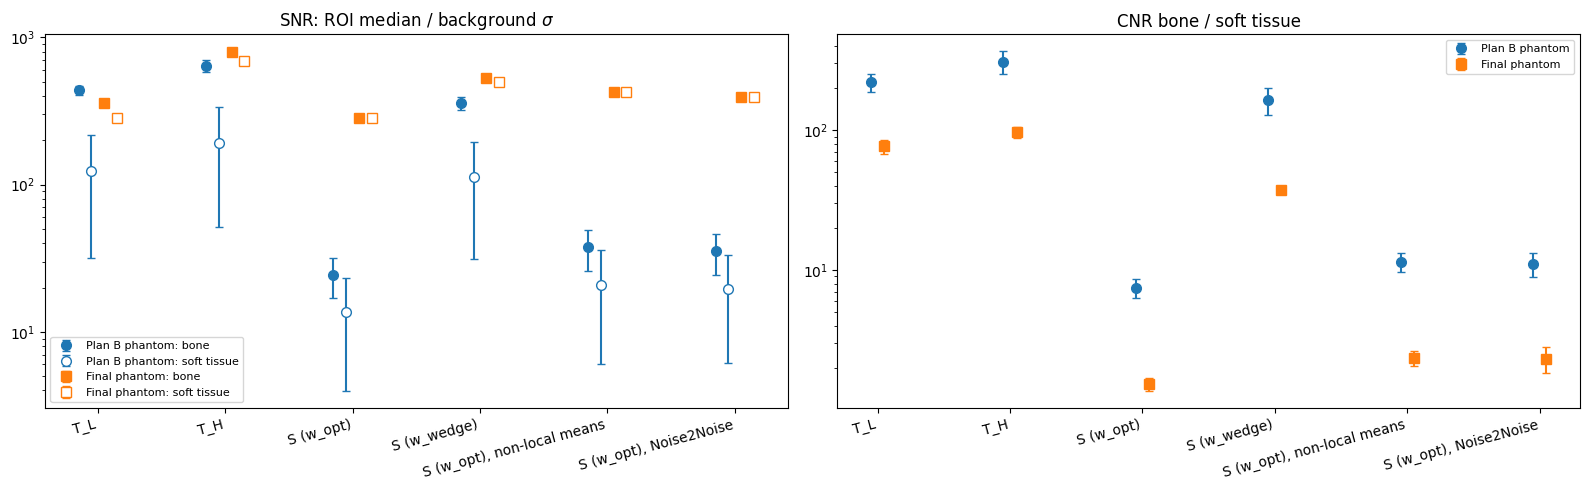

Effective energies fitted to the tray cells: E_L = 31.8 keV, E_H = 41.2 keV (0.5 x kVp would be 30 and 60 keV); rms error of log kappa 0.030


,contents,kappa_measured,kappa_theory,kappa_min,kappa_max,measured / theory,kappa_fitted_E,measured / fitted
cell,,,,,,,,
Red 3L,Resin,0.932,0.830,0.779,0.876,1.122,0.915,1.018
Red 3R,Resin + red food colouring,0.926,0.830,0.779,0.876,1.115,0.915,1.011
Red 4L,Candle wax,0.880,0.752,0.672,0.819,1.170,0.872,1.009
Red 4R,Silicone putty,1.214,NaN,NaN,NaN,NaN,NaN,NaN
Red 5L,Coconut oil + beeswax (1:1),0.895,0.786,0.719,0.843,1.139,0.891,1.004
Red 5R,Beeswax + coconut oil (2:1),0.884,0.780,0.711,0.839,1.133,0.888,0.995
Red 6L,Coconut oil,0.907,0.804,0.743,0.856,1.128,0.901,1.006
Red 6R,Beeswax,0.860,0.768,0.695,0.831,1.119,0.881,0.975
Red 1R,Water reference,1.000,1.000,1.000,1.000,1.000,1.000,1.000


,phantom,w_bone,w_opt,w_wedge_min,w_wedge_max,w_wedge,w (fitted E),w_opt / w_wedge,w_opt / w (fitted E)
ROI,,,,,,,,,
Bone shaft,Plan B phantom,0.671,0.675,0.352,0.381,0.354,0.669,1.907,1.009
Bone head,Plan B phantom,0.723,0.721,0.352,0.381,0.354,0.669,2.037,1.078
Bone head,Final phantom,0.514,0.520,0.337,0.359,0.338,0.630,1.540,0.825
Bone joint,Final phantom,0.543,0.540,0.337,0.359,0.338,0.630,1.599,0.857


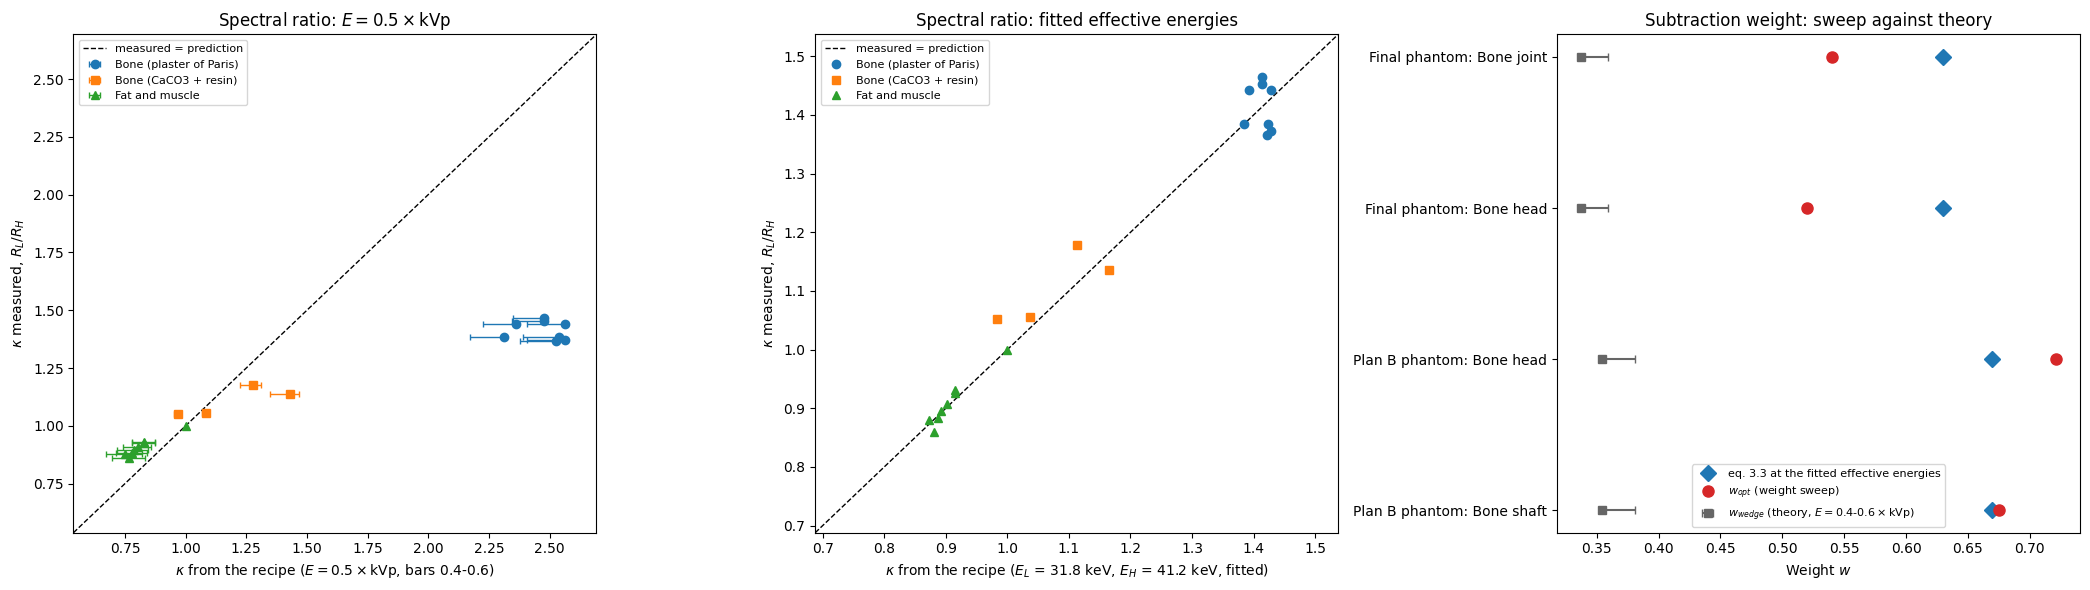

Humerus ROIs rejected (missed the shaft or the background is not air): image1 (138).png, image2 (18).png


,K,IQR low,IQR high,K / humerus median
data,,,,
Humerus radiographs (median of n = 12),0.396,0.314,0.526,1.000
"Plan B phantom, T_L (mean of its bone ROIs)",1.010,NaN,NaN,2.551
"Plan B phantom, T_H (mean of its bone ROIs)",0.921,NaN,NaN,2.326
"Final phantom, T_L (mean of its bone ROIs)",0.270,NaN,NaN,0.681
"Final phantom, T_H (mean of its bone ROIs)",0.139,NaN,NaN,0.351


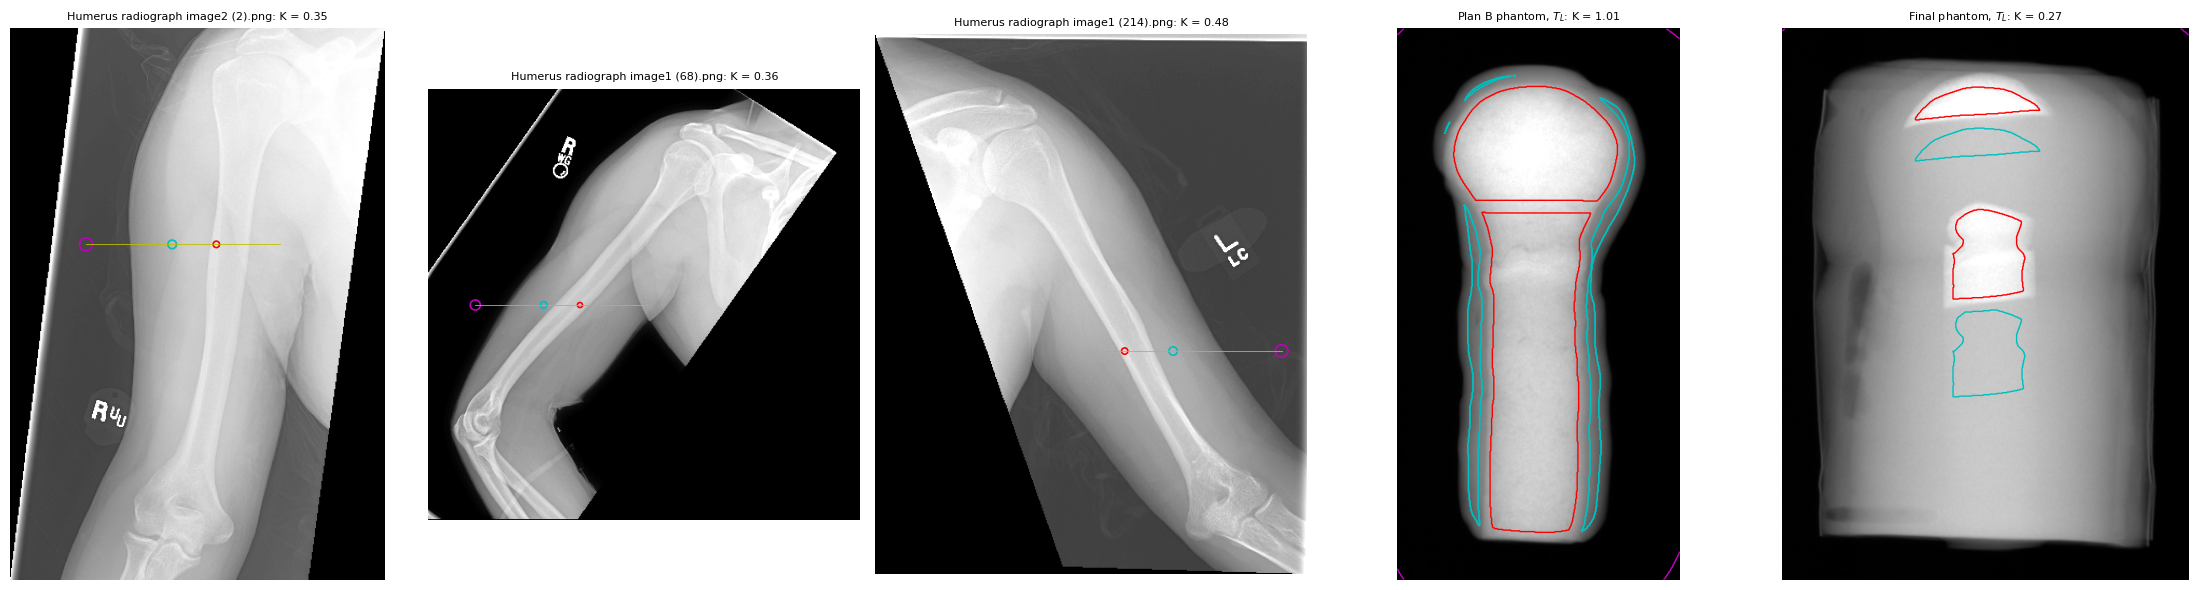

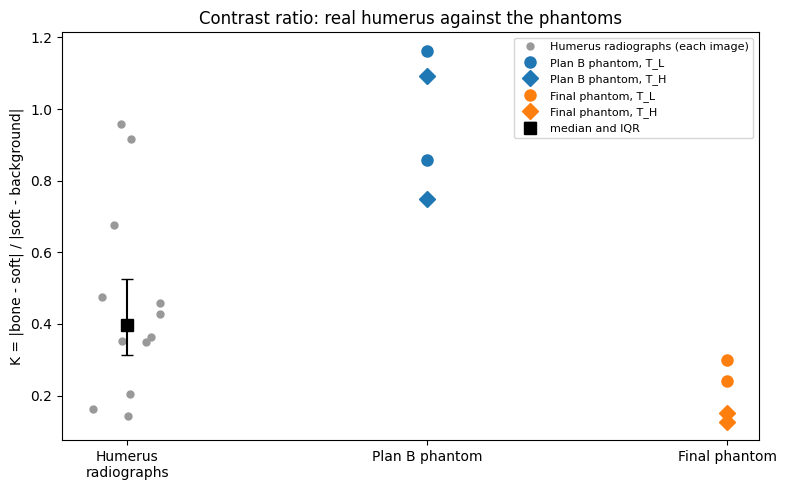

In [8]:
# ========================================================================================================

# Phase 7: Validation

"""Validation stage (Implementation chapter, Validation section; Modules/Validation.py).
1. CNR and SNR (eq. metrics: ROI median over the standard deviation of the background band) of the phantom before bone
   suppression (T_L, T_H) and after it (S at w_opt, S at the theoretical w_wedge and the two best denoised versions of S),
   for bone vs soft tissue and soft tissue vs background. The maps are zero at the background band, so the SNR of the soft
   tissue equals its CNR against the background. The noise of S is compared with the prediction for independent noise in the
   two scans, and the correlation of the two scans' background noise is measured (a positive correlation, e.g. a pattern
   shared by both scans, lowers sigma_S below the prediction).
2. Theory, ice-tray mode and phantom mode: the spectral ratio kappa = R_L / R_H of every tray cell against the value
   predicted from its recipe (the density cancels in kappa, so the cured densities, which were not measured, are not
   needed), and w_opt of each phantom against w_wedge (eq. 3.3).
3. Open-source data: how the phantom looks next to conventional radiographs of a real humerus (Kaggle humerus fracture
   dataset, non-fractured originals). Grey levels and CNR cannot be compared between the Lodox and another system, so K of
   the real humerus shaft, K = |bone - soft tissue| / |soft tissue - background| (independent of the gain, offset and
   polarity of the image), is compared with K of the phantoms' thickness maps, and the images are shown side by side. T_L
   (60 kVp) is the closest to a conventional humerus exposure. The clinical images are processed 8-bit PNGs (unknown display
   curve, often clipped air), so this comparison is indicative only.
   The images are downloaded on the first run into ../Open Source Images and the ROIs are saved next to them (rois.json), so
   every run uses the same regions. The ROIs of a new image are found from two clicked points: set CLICK_ROIS = True (with
   %matplotlib qt). The QC overlays of every ROI are saved to the output folder."""

# 1. CNR and SNR: the phantom before and after bone suppression ---------------------------------------------------------
cnr_tables, summaries, noise_rows = [], [], []
for name, p in phantoms.items():
    rois = p['mask'].rois
    background = rois['Phantom background']
    variants = {'T_L': thickness_maps[name]['low'], 'T_H': thickness_maps[name]['high'],
                'S (w_opt)': suppressed[name]['S'], 'S (w_wedge)': sweeps[name].subtract(p['w_wedge']),
                'S (w_opt), non-local means': denoised[name]['Non-local means (medium)'],
                'S (w_opt), Noise2Noise': denoised[name]['Noise2Noise']}
    t = Validation.metrics_table(variants, rois, list(p['bones'].items()) + list(p['soft'].items()), 'Phantom background')
    bone_cols = [f'CNR {a} / {b}' for a, b in p['bones'].items()]
    soft_cols = [f'CNR {a} / {b}' for a, b in p['soft'].items()]
    s = pd.DataFrame({'sigma_bg': t['sigma_bg'],
                      'SNR bone': t[[f'SNR {a}' for a in p['bones']]].mean(axis=1),
                      'SNR soft tissue': t[[f'SNR {a}' for a in p['soft']]].mean(axis=1),
                      'CNR bone / soft tissue': t[bone_cols].mean(axis=1), 'sd bone': t[bone_cols].std(axis=1),
                      'CNR soft tissue / background': t[soft_cols].mean(axis=1), 'sd soft': t[soft_cols].std(axis=1)})
    for c in ('SNR bone', 'CNR bone / soft tissue', 'CNR soft tissue / background', 'sigma_bg'):
        s[f'{c} (/ T_H)'] = s[c] / s.loc['T_H', c]
    t.insert(0, 'phantom', name)
    s.insert(0, 'phantom', name)
    cnr_tables.append(t)
    summaries.append(s)
    noise_rows.append(dict(phantom=name, w_opt=suppressed[name]['w'],
                           **Validation.noise_check(thickness_maps[name]['low'], thickness_maps[name]['high'], background,
                                                    suppressed[name]['w'])))
cnr_table, cnr_summary = pd.concat(cnr_tables), pd.concat(summaries)
noise_check = pd.DataFrame(noise_rows).set_index('phantom')
display(cnr_summary.round(3))
display(noise_check.round(4))
cnr_table.to_csv(os.path.join(output_folder, 'validation_cnr_snr.csv'))
cnr_summary.to_csv(os.path.join(output_folder, 'validation_cnr_summary.csv'))
noise_check.to_csv(os.path.join(output_folder, 'validation_noise.csv'))

# SNR and bone CNR of each phantom before and after suppression: mean of its ROIs, bars = range over the ROIs. The series
# are side by side, as the bone and soft-tissue SNR coincide once the bone is removed
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
series = [[], []]
for k, (name, p) in enumerate(phantoms.items()):
    series[0] += [(name, k, [f'SNR {a}' for a in p['bones']], f'C{k}', f'{name}: bone'),
                  (name, k, [f'SNR {a}' for a in p['soft']], 'white', f'{name}: soft tissue')]
    series[1] += [(name, k, [f'CNR {a} / {b}' for a, b in p['bones'].items()], f'C{k}', name)]
for ax, entries, title in zip(axes, series, ['SNR: ROI median / background $\sigma$', 'CNR bone / soft tissue']):
    for j, (name, k, columns, fill, label) in enumerate(entries):
        v = cnr_table.loc[cnr_table['phantom'] == name, columns]
        mean = v.mean(axis=1)
        x = np.arange(len(v)) + 0.1 * (j - (len(entries) - 1) / 2)
        ax.errorbar(x, mean, yerr=[mean - v.min(axis=1), v.max(axis=1) - mean], fmt='os'[k], color=f'C{k}', mfc=fill,
                    ms=7, capsize=3, label=label)
    ax.set_xticks(range(len(v)))
    ax.set_xticklabels(v.index, rotation=15, ha='right')
    ax.set_yscale('log')
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 2. Theory: ice-tray mode (spectral ratio) and phantom mode (subtraction weight) ---------------------------------------
composition = pd.read_csv(os.path.join('attenuation', 'generated', 'oct21', 'composition.csv'))
kappa = Validation.spectral_ratio_table(cell_results, composition, kvp_low, kvp_high)

"""The measured kappa is pulled towards 1 for every material (bone below theory, fats above), so the two presets are closer
in effective energy than 0.5 x kVp. The pair of effective energies that best fits all the cells is found, and eq. 3.3 is
evaluated at it: a prediction of w for the phantoms from the trays alone. Bone signatures: plan B, the bone mixture on top of
the silicone (its density cancels); final phantom, CaCO3 replacing resin along the path (assumed densities 2.71 and
1.15 g/cm3; w changes by less than 0.02 between 2.0-2.71 and 1.10-1.20 g/cm3)."""
e_low, e_high, rms, kappa['kappa_fitted_E'] = Validation.fit_effective_energies(kappa)
kappa['measured / fitted'] = kappa['kappa_measured'] / kappa['kappa_fitted_E']
print(f"Effective energies fitted to the tray cells: E_L = {e_low:.1f} keV, E_H = {e_high:.1f} keV "
      f"(0.5 x kVp would be {0.5 * kvp_low:.0f} and {0.5 * kvp_high:.0f} keV); rms error of log kappa {rms:.3f}")
display(kappa.drop(columns='material').round(3))
kappa.drop(columns='material').to_csv(os.path.join(output_folder, 'validation_spectral_ratio.csv'))

bone_signature = {
    'Plan B phantom': dict(material=(Bone_suppression.BONE_MATERIALS['Eggshell + PoP + water (1:1:2.5)'], 1.0)),
    'Final phantom': dict(material=({'CaCO3': 1.0}, 2.71), displaced=({'C21H24O4': 1.0}, 1.15)),
}
w_check = results[['phantom', 'w_bone', 'w_opt', 'w_wedge_min', 'w_wedge_max']].copy()
w_check['w_wedge'] = [phantoms[n]['w_wedge'] for n in w_check['phantom']]
w_check['w (fitted E)'] = [Validation.w_at(e_low, e_high, **bone_signature[n]) for n in w_check['phantom']]
w_check['w_opt / w_wedge'] = w_check['w_opt'] / w_check['w_wedge']
w_check['w_opt / w (fitted E)'] = w_check['w_opt'] / w_check['w (fitted E)']
display(w_check.round(3))
w_check.to_csv(os.path.join(output_folder, 'validation_weights.csv'))

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
Validation.parity_plot(kappa, axes[0], title='Spectral ratio: $E = 0.5\\times$kVp')
Validation.parity_plot(kappa, axes[1], column='kappa_fitted_E', band=False,
                       xlabel=f'$\\kappa$ from the recipe ($E_L$ = {e_low:.1f} keV, $E_H$ = {e_high:.1f} keV, fitted)',
                       title='Spectral ratio: fitted effective energies')
ax, y = axes[2], np.arange(len(w_check))
ax.errorbar(w_check['w_wedge'], y, xerr=[w_check['w_wedge'] - w_check['w_wedge_min'], w_check['w_wedge_max'] - w_check['w_wedge']],
            fmt='s', color='0.4', capsize=3, label='$w_{wedge}$ (theory, $E = 0.4$-$0.6\\times$kVp)')
ax.plot(w_check['w (fitted E)'], y, 'D', color='C0', ms=8, label='eq. 3.3 at the fitted effective energies')
ax.plot(w_check['w_opt'], y, 'o', color='C3', ms=8, label='$w_{opt}$ (weight sweep)')
ax.set_yticks(y)
ax.set_yticklabels([f'{p}: {r}' for r, p in zip(w_check.index, w_check['phantom'])])
ax.set_xlabel('Weight $w$')
ax.set_title('Subtraction weight: sweep against theory')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 3. Open-source data: the phantom against conventional humerus radiographs ---------------------------------------------
open_source = os.path.join('..', 'Open Source Images')
CLICK_ROIS = False

# Humerus radiographs: contrast ratio K. ROIs from two points per image (air next to the arm, a point beyond the shaft)
humerus_folder = os.path.join(open_source, 'Humerus fractures (Kaggle)')
humerus_files = ['image1 (10).png', 'image1 (138).png', 'image1 (177).png', 'image1 (214).png', 'image1 (233).png',
                 'image1 (252).png', 'image1 (290).png', 'image1 (68).png', 'image1 (87).png', 'image2 (122).png',
                 'image2 (160).png', 'image2 (18).png', 'image2 (2).png', 'image2 (218).png']
for f in humerus_files:
    Validation.kaggle_file(Validation.HUMERUS, f'original_data/original_data/no fracturados/{f}',
                           os.path.join(humerus_folder, 'no fracturados', f))

def load_humerus(f):
    return Validation.load_grey(os.path.join(humerus_folder, 'no fracturados', f))

def place_limb(f):
    if not CLICK_ROIS:
        raise RuntimeError(f'No ROIs saved for {f}: set CLICK_ROIS = True to click them')
    image = load_humerus(f)
    air, far = [(r['row'], r['col']) for r in Validation.click_rois(image, ['air next to the arm', 'a point beyond the shaft'],
                                                                     [3, 3], f)]
    return Validation.line_rois(image, air, far) + [dict(name='line', air=air, far=far)]

humerus_rois = Validation.roi_file(os.path.join(humerus_folder, 'rois.json'), humerus_files, place_limb)
humerus = pd.DataFrame([dict(image=f, **Validation.limb_metrics(load_humerus(f), humerus_rois[f])) for f in humerus_files]
                       ).set_index('image')
humerus.to_csv(os.path.join(output_folder, 'validation_humerus.csv'))
if (~humerus['valid']).any():
    print(f"Humerus ROIs rejected (missed the shaft or the background is not air): {', '.join(humerus.index[~humerus['valid']])}")

# The phantoms' K on their thickness maps, with the bone, soft-tissue and background ROIs of part 1
phantom_K = pd.DataFrame([dict(phantom=name, bone=bone, image=label,
                               **Validation.contrast_ratio(thickness_maps[name][k], p['mask'].rois[bone], p['mask'].rois[soft],
                                                           p['mask'].rois['Phantom background']))
                          for name, p in phantoms.items() for bone, soft in p['bones'].items()
                          for k, label in [('low', 'T_L'), ('high', 'T_H')]])
phantom_K.to_csv(os.path.join(output_folder, 'validation_phantom_K.csv'))

valid = humerus['K'].dropna()
k_summary = pd.DataFrame([{'data': f'Humerus radiographs (median of n = {len(valid)})', 'K': valid.median(),
                           'IQR low': valid.quantile(0.25), 'IQR high': valid.quantile(0.75)}]
                         + [{'data': f'{n}, {i} (mean of its bone ROIs)', 'K': g['K'].mean()}
                            for (n, i), g in phantom_K.groupby(['phantom', 'image'], sort=False)]).set_index('data')
k_summary['K / humerus median'] = k_summary['K'] / valid.median()
display(k_summary.round(3))
k_summary.to_csv(os.path.join(output_folder, 'validation_humerus_summary.csv'))

# QC overlay of every humerus ROI (saved)
colours = {'Bone': 'r', 'Soft': 'c', 'Background': 'm'}
n_col = 5
n_row = int(np.ceil(len(humerus_files) / n_col))
fig, axes = plt.subplots(n_row, n_col, figsize=(4 * n_col, 4.4 * n_row))
for ax, f in zip(axes.ravel(), humerus_files):
    Validation.show_rois(load_humerus(f), humerus_rois[f], ax, f, colours)
for ax in axes.ravel()[len(humerus_files):]:
    ax.axis('off')
plt.tight_layout()
fig.savefig(os.path.join(output_folder, 'validation_rois_humerus.png'), dpi=80)
plt.close(fig)

# The phantoms (T_L) next to the humerus radiographs whose K is closest to the quartiles, with the ROIs of K
examples = [(valid - valid.quantile(q)).abs().idxmin() for q in (0.25, 0.5, 0.75)]
fig, axes = plt.subplots(1, len(examples) + len(phantoms), figsize=(4.5 * (len(examples) + len(phantoms)), 6))
for ax, f in zip(axes, examples):
    Validation.show_rois(load_humerus(f), humerus_rois[f], ax, f'Humerus radiograph {f}: K = {valid[f]:.2f}', colours)
for ax, (name, p) in zip(axes[len(examples):], phantoms.items()):
    rr, cc = np.nonzero(p['mask'].footprint)
    pad = int(round(10 / pixel_spacing))
    window = (slice(max(rr.min() - pad, 0), rr.max() + pad), slice(max(cc.min() - pad, 0), cc.max() + pad))
    T = thickness_maps[name]['low'][window]
    ax.imshow(T, cmap='gray', vmin=np.percentile(T, 1), vmax=np.percentile(T, 99))
    for roi, colour in ([(b, 'r') for b in p['bones']] + [(s, 'c') for s in p['bones'].values()]
                        + [('Phantom background', 'm')]):
        ax.contour(p['mask'].rois[roi][window], levels=[0.5], colors=colour, linewidths=1)
    ax.set_title(f"{name}, $T_L$: K = {k_summary.loc[f'{name}, T_L (mean of its bone ROIs)', 'K']:.2f}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

# K of every humerus radiograph against the phantoms
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.random.default_rng(1).uniform(-0.12, 0.12, len(valid)), valid, 'o', color='0.6', ms=5,
        label='Humerus radiographs (each image)')
ax.errorbar([0], [valid.median()], yerr=[[valid.median() - valid.quantile(0.25)], [valid.quantile(0.75) - valid.median()]],
            fmt='s', color='k', capsize=4, ms=8, label='median and IQR')
for k, name in enumerate(phantoms):
    for label, marker in [('T_L', 'o'), ('T_H', 'D')]:
        sel = phantom_K[(phantom_K['phantom'] == name) & (phantom_K['image'] == label)]
        ax.plot(np.full(len(sel), k + 1), sel['K'], marker, color=f'C{k}', ms=8, label=f'{name}, {label}')
ax.set_xticks(range(len(phantoms) + 1))
ax.set_xticklabels(['Humerus\nradiographs'] + list(phantoms))
ax.set_ylabel('K = |bone - soft| / |soft - background|')
ax.set_title('Contrast ratio: real humerus against the phantoms')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()